In [91]:
#%matplotlib widget

In [92]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
try:
    import mplcursors
except ImportError:
    mplcursors = None  # Необязательные подсказки на графиках Matplotlib
import plotly.graph_objects as go

from scipy.spatial.distance import jensenshannon

from sklearn.model_selection import train_test_split

from stepmix.stepmix import StepMix


from ccrs_codebook import ccrs_codebook as codebook

import json


In [93]:
codebook['ID_Q33_5']

{'Details': 'There are secret organizations that greatly\ninfluence political decisions.',
 'Coding': 'Likert scale item:\n0 = Certainly not\n10 = Certain'}

In [94]:
df = pd.read_csv('CCRS Dataset.csv')
#df = pd.read_csv('EVS_WVS_Joint_Csv_v5_0.csv')

In [95]:
df.shape

(8101, 153)

In [96]:
df.sample(10)

,ResponseID,Language,ID_Q1,ID_Q2,ID_Q3,ID_Q4,ID_Q5,ID_Q6,ID_Q7,ID_Q8,...,ID_Q35_4,ID_Q36_1,ID_Q36_2,ID_Q36_3,ID_Q36_4,ID_Q36_5,ID_Q36_6,ID_Q36_7,ID_Q36_8,ID_Q36_9
2147,R_1GvPd6BFU9qOZL2,1,1,Canada,37.0,1.0,4.0,1.0,1.0,2.0,...,9.0,3.0,3.0,3.0,3.0,4.0,4.0,3.0,NaN,NaN
5015,R_10H3W2TG2sBLopa,4,6,Morocco,26.0,1.0,2.0,1.0,1.0,2.0,...,NaN,2.0,3.0,3.0,2.0,NaN,NaN,NaN,NaN,NaN
5620,R_3fOyIcjWV75IZw2,4,6,Morocco,29.0,0.0,4.0,1.0,1.0,2.0,...,NaN,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN
1808,R_3wMZo52hVdSA9wZ,5,8,Brazil,35.0,0.0,NaN,1.0,1.0,2.0,...,0.0,0.0,2.0,0.0,2.0,NaN,NaN,NaN,NaN,NaN
3477,R_2R52aM8mnMbGR5y,3,3,Germany,49.0,0.0,4.0,4.0,1.0,2.0,...,0.0,0.0,0.0,NaN,0.0,0.0,3.0,3.0,2.0,NaN
1821,R_5neZ510zUKD2m4h,5,8,Brazil,23.0,1.0,4.0,3.0,1.0,2.0,...,6.0,2.0,3.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN
920,R_soNLanT1zUrdATn,1,4,Australia,63.0,1.0,2.0,2.0,1.0,2.0,...,0.0,2.0,2.0,2.0,0.0,0.0,0.0,3.0,NaN,NaN
1856,R_Ab4BMxGOL5C2LhT,5,8,Brazil,58.0,0.0,NaN,1.0,1.0,2.0,...,0.0,0.0,1.0,0.0,3.0,NaN,NaN,NaN,NaN,NaN
886,R_qOcAeSy4qMxTIsN,1,4,Australia,21.0,0.0,4.0,2.0,1.0,2.0,...,0.0,2.0,2.0,3.0,2.0,0.0,3.0,2.0,NaN,NaN
7540,R_2U0mRW0GLZ7LExq,1,2,United States,41.0,0.0,4.0,2.0,1.0,2.0,...,3.0,2.0,1.0,2.0,3.0,3.0,2.0,2.0,3.0,2.0


In [97]:
codebook['ID_Q35'], codebook['ID_Q33'], codebook['ID_Q30']

({'Details': 'Radicalism Intention Scale (4-item scale\naverage)',
  'Coding': 'Continuous variable:\n0 = Lower intentions\n10 = Higher intentions'},
 {'Details': 'Conspiracy Mentality Scale (5-item scale\naverage)',
  'Coding': 'Continuous variable:\n0 = Low conspiracy mentality\n10 = High conspiracy mentality'},
 {'Details': 'Need for cognitive closure (15-item scale\naverage)\n*Mean score of ID_Q38_1 to ID_Q38_15',
  'Coding': 'Continuous variable:\n1 = Low need for cognitive closure\n5 = High need for cognitive closure'})

In [98]:
df.describe()

,Language,ID_Q1,ID_Q3,ID_Q4,ID_Q5,ID_Q6,ID_Q7,ID_Q8,ID_Q9,ID_Q10,...,ID_Q35_4,ID_Q36_1,ID_Q36_2,ID_Q36_3,ID_Q36_4,ID_Q36_5,ID_Q36_6,ID_Q36_7,ID_Q36_8,ID_Q36_9
count,8101.000000,8101.000000,8022.000000,7862.000000,7839.000000,7890.000000,7816.000000,7981.000000,8088.000000,8050.000000,...,7137.000000,8040.000000,8051.000000,8046.000000,8048.000000,5976.000000,5056.000000,5053.000000,2022.000000,1001.000000
mean,2.312060,4.495371,40.743082,0.517044,3.623166,2.035361,0.913127,1.781105,2.357938,5.410559,...,2.818131,1.408333,1.423798,1.353716,1.713966,1.580823,1.530854,1.660202,1.247280,1.693307
std,1.541408,2.280380,15.534902,0.499741,0.938722,1.124697,0.281667,0.517923,2.130083,2.543353,...,3.301887,1.263142,1.249994,1.308068,1.305729,1.390401,1.348127,1.337797,1.267795,1.321683
min,1.000000,1.000000,18.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,3.000000,28.000000,0.000000,3.000000,1.000000,1.000000,1.000000,1.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,4.000000,37.000000,1.000000,4.000000,2.000000,1.000000,2.000000,1.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000
75%,4.000000,6.000000,53.000000,1.000000,4.000000,3.000000,1.000000,2.000000,3.000000,7.000000,...,5.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,3.000000,2.000000,3.000000
max,5.000000,8.000000,99.000000,1.000000,5.000000,5.000000,1.000000,3.000000,9.000000,10.000000,...,10.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000


In [99]:
df.describe(include=['object'])

/tmp/ipykernel_13196/3011300674.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['object'])


,ResponseID,ID_Q2
count,8101,8101
unique,8101,8
top,R_03b0zUoNhf6lvH3,Morocco
freq,1,1072


In [100]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8101 entries, 0 to 8100
Columns: 153 entries, ResponseID to ID_Q36_9
dtypes: float64(149), int64(2), str(2)
memory usage: 9.5 MB


**ResponseID** - уникальный идентификатор респондента, не несёт никакой полезной информации  
**ID_Q2** - дублирует **ID_Q1**, коллинеарен  

Удалим эти колонки

In [101]:
df = df.drop(columns=['ResponseID', 'ID_Q2'])

Заменим все пропуски на `-1` - это будет техническое значение

In [102]:
for col in df.columns:
    df.loc[:, col] = df[col].fillna(-1)

In [103]:
df = df.drop_duplicates()

In [104]:
df.shape

(8098, 151)

In [105]:
df.isna().any(axis=1).sum()

np.int64(0)

In [106]:
df['conspiracy_index'] = df['ID_Q32'] + df['ID_Q33']

/tmp/ipykernel_13196/170055460.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['conspiracy_index'] = df['ID_Q32'] + df['ID_Q33']


In [107]:
codebook['ID_Q32'], codebook['ID_Q33']

({'Details': 'Conspiracy belief scale (14-item scale\naverage)',
  'Coding': 'Continuous variable:\n0 = Low conspiracy beliefs\n4 = High conspiracy beliefs'},
 {'Details': 'Conspiracy Mentality Scale (5-item scale\naverage)',
  'Coding': 'Continuous variable:\n0 = Low conspiracy mentality\n10 = High conspiracy mentality'})

In [108]:
normal = df[df['conspiracy_index'] <= df['conspiracy_index'].quantile(0.25)]

In [109]:
marginal = df[df['conspiracy_index'] >= df['conspiracy_index'].quantile(0.75)]

In [110]:
marginal.to_csv('marginal.csv')

In [111]:
normal.shape, marginal.shape

((2041, 152), (2030, 152))

In [112]:
def js_distance(df1: pd.DataFrame, df2: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Расстояние Дженсена–Шеннона (base=2) между долями ответов по каждому вопросу."""
    data = []
    for col in cols:
        # -1 в исходном CCRS — технический пропуск; пропуски исключаются из долей.
        v1 = pd.to_numeric(df1[col], errors='coerce').replace(-1, np.nan)
        v2 = pd.to_numeric(df2[col], errors='coerce').replace(-1, np.nan)
        prob1 = v1.value_counts(normalize=True).sort_index()
        prob2 = v2.value_counts(normalize=True).sort_index()
        if prob1.empty or prob2.empty:
            continue
        prob1_aligned, prob2_aligned = prob1.align(prob2, fill_value=0.0)
        data.append({
            'column_name': col,
            'js_distance': float(jensenshannon(prob1_aligned, prob2_aligned, base=2)),
            'n_1': int(v1.notna().sum()),
            'n_2': int(v2.notna().sum()),
        })
    if not data:
        raise ValueError('Нет общих вопросов с непустыми числовыми ответами в обоих датасетах')
    return (pd.DataFrame(data).sort_values('js_distance', ascending=False)
            .set_index('column_name'))


In [113]:
def plot_opinion_dist(
        df1: pd.DataFrame,
        df2: pd.DataFrame,
        js_df: pd.DataFrame, 
        interval: tuple[float, float],
        title: str,
        codebook: dict[str, dict[str, str]],
        group_names: tuple[str, str] = ('normal', 'marginal'),
        n_pics: int = 3,
        pics_on_line: int = 3):
    
    # Отбираем DataFrame с колонками и их JSD, попавшими в нужный интервал
    mask = (js_df['js_distance'] >= interval[0]) & (js_df['js_distance'] < interval[1])
   
    cols = js_df.loc[mask, ['js_distance']].head(n_pics)
    
    # Если ничего не нашлось, сразу выходим
    if cols.empty:
        return
        
    # Считаем количество строк для сетки графиков
    n_rows = (len(cols) + pics_on_line - 1) // pics_on_line
    fig, axes = plt.subplots(n_rows, pics_on_line, figsize=(pics_on_line * 6, n_rows * 5))
    axes = np.atleast_1d(axes).flatten()

    # Главный заголовок строго по центру
    fig.suptitle(
        f'{title} (JS Distance: {interval[0]:.2f} - {interval[1]:.2f})', 
        fontsize=16, 
        x=0.5,
        horizontalalignment='center'
    )

    # Итерируемся по строкам нашего DataFrame `cols`
    for i, row in enumerate(cols.itertuples()):
        col = row.Index
        col_jsd = row.js_distance
        
        ax = axes[i]
        v1 = pd.to_numeric(df1[col], errors='coerce').replace(-1, np.nan).dropna()
        v2 = pd.to_numeric(df2[col], errors='coerce').replace(-1, np.nan).dropna()
        unique_values = np.union1d(v1.unique(), v2.unique())
        is_discrete = (len(unique_values) <= 25 and
                       np.allclose(unique_values, np.round(unique_values)))
        common_range = (float(min(v1.min(), v2.min())),
                        float(max(v1.max(), v2.max())))
        for v, label, w, c in [(v1, group_names[0], 0.6, '#56b9ca'),
                               (v2, group_names[1], 0.3, '#ca5659')]:
            kwargs = dict(x=v, weights=np.ones(len(v))*100/len(v), label=label,
                          color=c, alpha=0.65, ax=ax)
            if is_discrete:
                kwargs.update(discrete=True, shrink=w)
            else:
                kwargs.update(bins=15, binrange=common_range)
            sns.histplot(**kwargs)
        if is_discrete:
            ax.set_xticks(unique_values)
        ax.set_ylabel('Percentage (%)')
        
        # Добавляем индивидуальный JSD в название графика
        base_title = codebook[col]['Details'] if codebook and col in codebook else col
        ax.set_title(f'{base_title}\nJSD: {col_jsd:.3f}', fontsize=11)
        
        ax.legend(title='Source')

        if codebook and col in codebook and 'Coding' in codebook[col]:
            ax.text(1.02, 0.5, 'Legend:\n' + codebook[col]['Coding'], transform=ax.transAxes, 
                verticalalignment='center', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    # Прячем неиспользованные (пустые) ячейки в сетке графиков
    for j in range(len(cols), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout(rect=(0, 0, 1, 0.90))
    plt.show()


In [114]:
def plot_mode_opinion_dist(
        df1: pd.DataFrame,
        df2: pd.DataFrame,
        js_df: pd.DataFrame,
        group_names: tuple[str, str] = ('normal mode', 'marginal mode')):

    # Находим пересечение колонок, чтобы избежать ошибок отсутствующих ключей
    columns = sorted(js_df.index.tolist())
    
    # Считаем моду для каждой колонки
    modes1 = [pd.to_numeric(df1[col], errors='coerce').replace(-1, np.nan).mode().iloc[0] for col in columns]
    modes2 = [pd.to_numeric(df2[col], errors='coerce').replace(-1, np.nan).mode().iloc[0] for col in columns]
    
    # Извлекаем дистанцию JSD только для отфильтрованных колонок
    distances_list = js_df.loc[columns, 'js_distance'].tolist()

    # Строим график
    fig, ax1 = plt.subplots(figsize=(25, 10))
    
    # Создаем вторую ось Y для JSD (общая ось X)
    ax2 = ax1.twinx()
    
    # Рисуем моды на левой оси ax1
    line1, = ax1.plot(columns, modes1, marker='o', ms=3, linewidth=1, color='#56b9ca', label=group_names[0])
    line2, = ax1.plot(columns, modes2, marker='s', ms=3, linewidth=1, color='#ca5659', label=group_names[1])
    
    # Рисуем JSD на правой оси ax2 (исправлена ошибка конвертации типа)
    line3, = ax2.plot(columns, distances_list, marker='^', ms=3, linewidth=1, color='#04030f', label='JS distance', linestyle='--')

    # Оформление заголовка и осей
    ax1.set_title('Сравнение мод и JSD по всем вопросам', fontsize=16, pad=15)
    ax1.set_xlabel('ID вопроса', fontsize=12)
    ax1.set_ylabel('Значение моды', fontsize=12)
    ax2.set_ylabel('JS distance', fontsize=12, color='#02010c')
    
    # Подсвечиваем шкалу JSD цветом её линии
    ax2.tick_params(axis='y', labelcolor='#04030f')
    ax2.set_ylim(0, 1)  # JSD всегда в диапазоне [0, 1]

    # Настройка отступов и делений оси X
    ax1.margins(x=0.01)
    ax2.margins(x=0.01)

    ax1.set_xticks(columns)
    ax1.set_xticklabels(columns, rotation=90, ha='center', fontsize=9) 
    
    # Сетки (рисуем через ax1, чтобы они были на заднем плане)
    ax1.grid(axis='y', linestyle=':', alpha=0.6)
    ax1.grid(axis='x', linestyle='--', alpha=0.4) 
    
    # Объединяем легенды от двух разных осей в одну общую
    lines = [line1, line2, line3]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, title='Показатели', loc='upper left', fontsize=11)
    
    if mplcursors is not None:
        cursor = mplcursors.cursor([line1, line2, line3], hover=True)

    if mplcursors is not None:
        @cursor.connect("add")
        def on_add(sel):
            idx = int(sel.index)
            question_code = columns[idx]
            description = codebook.get(question_code, {}).get('Details', 'Нет описания')
            sel.annotation.set_text(f'{question_code}: {description}')
            sel.annotation.get_bbox_patch().set(fc='white', alpha=0.9, edgecolor='gray')

    plt.tight_layout()
    plt.show()

## Два независимых пайплайна

1. `compare_distributions(df1, df2)` — JSD и исходные графики; подходит для `normal` vs `marginal` и для синтетических ответов.
2. `compare_latent_structures(marginal, synthetic)` — StepMix **только на реальных маргиналах**, проекция синтетических ответов на те же классы, профили и внутриклассовые связи PhiK. Регрессий нет.

Функции принимают `DataFrame` или путь к CSV/Parquet. Все результаты сравнений можно повторно использовать и сохранить. Примеры вызовов — в конце ноутбука.

In [115]:
# Настройки первого пайплайна: прежняя визуализация и сравнение JSD
COMPARE_RAW_QUESTIONS_ONLY = True
COMPARE_SHOW_HISTOGRAMS = True
COMPARE_SHOW_PLOTLY = True       # False — отключить интерактивную визуализацию Plotly
COMPARE_SHOW_MATPLOTLIB_MODES = False
COMPARE_EXPORT = True
COMPARE_OUTPUT_DIR = 'ccrs_comparisons'


In [116]:
# Результаты каждой пары и средняя JSD сохраняются в comparison_history.
# Для воспроизводимого сравнения до и после дообучения в сводке
# учитывается пересечение вопросов всех выполненных запусков.
comparison_history = {}  # при повторном запуске всей тетради история обнуляется


In [117]:
thresholds = {
    'Полное единообразие'       : 0.10,
    'Схожие мнения'             : 0.20,
    'Заметные разногласия'      : 0.35,
    'Глубокий раскол'           : 0.50,
    'Противоположные позиции'   : 0.80,
    'Абсолютная полярность'     : 1.00 + 1e-6
}

In [118]:
bins = [0.0] + list(thresholds.values())
js_distance_intervals = list(zip(bins, bins[1:]))
titles = list(thresholds.keys())

In [119]:
# Построение интервалов теперь выполняется внутри compare_datasets(...).
# Параметры plot_opinion_dist(...) и перечень интервалов выше сохранены.


In [120]:

def plot_mode_opinion_dist_plotly(
        df1: pd.DataFrame,
        df2: pd.DataFrame,
        js_df: pd.DataFrame,
        codebook: dict,  # Передаем словарь в функцию явным образом
        group_names: tuple[str, str] = ('normal mode', 'marginal mode')):

    # Находим пересечение колонок
    columns = sorted(js_df.index.tolist())
    
    # Считаем моды и JSD
    modes1 = [pd.to_numeric(df1[col], errors='coerce').replace(-1, np.nan).mode().iloc[0] for col in columns]
    modes2 = [pd.to_numeric(df2[col], errors='coerce').replace(-1, np.nan).mode().iloc[0] for col in columns]
    distances_list = js_df.loc[columns, 'js_distance'].tolist()

    # Формируем список описаний из словаря codes для всплывающих подсказок
    descriptions = [codebook.get(col, {}).get('Details', 'Нет описания') for col in columns]

    # Шаблон подсказки (HTML-разметка): <br> — перенос строки
    # %{x} — ID вопроса, %{y} — значение точки, %{customdata} — наше описание
    hover_template = "<b>Код:</b> %{x}<br><b>Значение:</b> %{y}<br><b>Описание:</b> %{customdata}<extra></extra>"

    fig = go.Figure()

    # Рисуем Моду 1 (Левая ось Y)
    fig.add_trace(go.Scatter(
        x=columns, y=modes1, name=group_names[0],
        mode='lines+markers', marker=dict(symbol='circle', size=6, color='#56b9ca'),
        line=dict(width=1), customdata=descriptions, hovertemplate=hover_template
    ))

    # Рисуем Моду 2 (Левая ось Y)
    fig.add_trace(go.Scatter(
        x=columns, y=modes2, name=group_names[1],
        mode='lines+markers', marker=dict(symbol='square', size=6, color='#ca5659'),
        line=dict(width=1), customdata=descriptions, hovertemplate=hover_template
    ))

    # Рисуем JSD (Правая ось Y)
    fig.add_trace(go.Scatter(
        x=columns, y=distances_list, name='JS distance', yaxis='y2',
        mode='lines+markers', marker=dict(symbol='triangle-up', size=6, color='#04030f'),
        line=dict(width=1, dash='dash'), customdata=descriptions, hovertemplate=hover_template
    ))

    # Настройка осей и внешнего вида (заменяет все ваши настройки сеток, шрифтов и двойных осей)
    fig.update_layout(
        title=dict(text='Сравнение мод и JSD по всем вопросам', x=0.5, font=dict(size=16)),
        xaxis=dict(title='ID вопроса', tickangle=90, type='category', automargin=True),
        yaxis=dict(title='Значение моды'),
        yaxis2=dict(title='JS distance', overlaying='y', side='right', range=[0, 1]), # Вторая ось Y
        legend=dict(title='Показатели', x=0.01, y=0.99, bgcolor='rgba(255,255,255,0.8)'),
        margin=dict(l=50, r=50, t=50, b=50),
        height=600, # График будет идеально вписываться в экран по высоте
        template='plotly_white' # Чистая белая тема с аккуратной сеткой
    )
    # Перед fig.show() добавьте эту строку:
    fig.show()  # корректный рендерер выбирается Jupyter / VS Code


In [121]:
from pathlib import Path

# Набор столбцов согласуется автоматически и не зависит от их порядка в файлах.
def _load_comparison_dataset(data):
    if isinstance(data, pd.DataFrame):
        frame = data.copy()
    elif isinstance(data, (str, Path)):
        path = Path(data)
        if not path.is_file():
            raise FileNotFoundError(f'Не найден файл для сравнения: {path}')
        if path.suffix.lower() == '.parquet':
            frame = pd.read_parquet(path)
        elif path.suffix.lower() == '.csv':
            frame = pd.read_csv(path)
        else:
            raise ValueError(f'Поддерживаются только CSV и Parquet: {path}')
    else:
        raise TypeError('Датасет: pandas.DataFrame либо путь к CSV/Parquet')
    frame.columns = frame.columns.astype(str).str.strip()
    if frame.columns.duplicated().any():
        raise ValueError('После нормализации названий найдены дубли столбцов')
    if frame.empty:
        raise ValueError('Для сравнения подан пустой датасет')
    return frame


def _select_comparison_columns(df1, df2, raw_only=True):
    # Производные шкалы определяются по исходному codebook, без зависимости от StepMix.
    composites = {c for c in codebook if any(p.startswith(c + '_') for p in codebook)}
    exclusions = {'ResponseID', 'ID_Q2', 'ID_Q24', 'Language', 'conspiracy_index'}
    all_questions = {c for c in codebook if c not in exclusions and not c.startswith('ID_Q36_')}
    if raw_only:
        all_questions -= composites
    common = sorted(all_questions & set(df1.columns) & set(df2.columns))
    missing_in_second = sorted((all_questions & set(df1.columns)) - set(df2.columns))
    missing_in_first = sorted((all_questions & set(df2.columns)) - set(df1.columns))
    if not common:
        raise ValueError('Нет общих ID_Q* вопросов: проверь названия колонок синтетических ответов')
    return common, missing_in_first, missing_in_second


def compare_datasets(
    df1, df2, group_names=('Маргинальные (CCRS)', 'Сравниваемая выборка'),
    comparison_id='comparison', raw_only=True,
    histograms=True, plotly_modes=True, matplotlib_modes=False,
    export=True, output_dir='ccrs_comparisons'
):
    """Один запуск: две таблицы -> JS по общим исходным вопросам -> прежние графики.

    Возвращает JSD и метаданные. Параллельное сравнение нескольких запусков
    делается по ОБЩИМ вопросам через compare_history_summary().
    """
    left = _load_comparison_dataset(df1)
    right = _load_comparison_dataset(df2)
    features, missing_left, missing_right = _select_comparison_columns(left, right, raw_only)

    # Запрещаем молча сравнивать строки вроде 'Strongly agree' вместо числовых кодов.
    for label, frame in ((group_names[0], left), (group_names[1], right)):
        nonempty = frame[features].notna().sum(axis=0)
        numeric = frame[features].apply(pd.to_numeric, errors='coerce')
        bad = nonempty[(nonempty > 0) & (numeric.notna().sum(axis=0) == 0)].index.tolist()
        if bad:
            raise ValueError(f'{label}: нет числовых ответов в колонках {bad[:10]}; нужна кодировка по CCRS')

    left = left[features].apply(pd.to_numeric, errors='coerce').replace(-1, np.nan)
    right = right[features].apply(pd.to_numeric, errors='coerce').replace(-1, np.nan)
    distances = js_distance(left, right, features)
    valid_features = distances.index.tolist()
    left = left[valid_features]
    right = right[valid_features]

    print(f'\nСравнение «{comparison_id}»: {group_names[0]} (n={len(left)}) / {group_names[1]} (n={len(right)})')
    print(f'Общих вопросов: {len(distances)}; средняя JS: {distances.js_distance.mean():.4f}; '
          f'медиана JS: {distances.js_distance.median():.4f}')
    if missing_right:
        print(f'Нет у второй выборки: {len(missing_right)} вопросов; например {missing_right[:8]}')
    if missing_left:
        print(f'Нет у первой выборки: {len(missing_left)} вопросов; например {missing_left[:8]}')
    display(distances)

    if histograms:
        for interval, title in zip(js_distance_intervals, titles):
            plot_opinion_dist(left, right, distances, interval, title,
                              codebook=codebook, group_names=group_names)
    if plotly_modes:
        plot_mode_opinion_dist_plotly(left, right, distances, codebook, group_names)
    if matplotlib_modes:
        plot_mode_opinion_dist(left, right, distances, group_names)

    result = {
        'comparison_id': comparison_id,
        'group_names': group_names,
        'n_first': len(left), 'n_second': len(right),
        'js_distances': distances,
        'n_questions': len(distances),
        'mean_js': float(distances.js_distance.mean()),
    }
    comparison_history[comparison_id] = result
    if export:
        export_dir = Path(output_dir)
        export_dir.mkdir(parents=True, exist_ok=True)
        safe_id = ''.join(c if c.isascii() and (c.isalnum() or c in '_-') else '_'
                          for c in comparison_id)
        distances.to_csv(export_dir / f'{safe_id}_js.csv', encoding='utf-8-sig')
    return result


def compare_history_summary():
    """Сопоставимая средняя JS только по пересечению вопросов всех запусков."""
    if not comparison_history:
        print('Сравнения ещё не запускались')
        return pd.DataFrame()
    js_matrix = pd.concat({key: value['js_distances']['js_distance']
                           for key, value in comparison_history.items()}, axis=1)
    shared = js_matrix.dropna()
    summary = pd.DataFrame([
        {
            'scenario': key,
            'n_1': r['n_first'], 'n_2': r['n_second'],
            'n_questions': r['n_questions'],
            'mean_js_own_questions': r['mean_js'],
            'n_questions_shared': len(shared),
            'mean_js_shared_questions': float(shared[key].mean()) if len(shared) else np.nan,
        }
        for key, r in comparison_history.items()
    ])
    display(summary.round(4))
    if len(js_matrix.columns) > 1 and len(shared):
        print('JSD по общим вопросам для сравнения сценариев:')
        display(shared.round(4))
    return summary


In [122]:
# Запуск сравнения перенесён в примеры в конце ноутбука.
# Функции из предыдущей ячейки используются без изменения.

In [123]:
codebook['ID_Q30_12']

{'Details': 'I find that establishing a consistent routine\nenables me to enjoy life more.',
 'Coding': 'Likert scale item:\n1 = Completely disagree\n5 = Completely agree'}

Некоторые признаки - не вопросы, а композитная оценка: среднее арифметическое от дочерних вопросов.  
Выделим эти признаки

In [124]:
composite_features = {}

all_features = codebook.keys()

for var in all_features:
    splitted = var.split('_')
    if len(splitted) == 3:
        parent = f'{splitted[0]}_{splitted[1]}'
        if parent in all_features:
            if parent in composite_features.keys():
                composite_features[parent].append(var)
            else:
                composite_features[parent] = [var]

In [125]:
profile_features = [
    'ID_Q1',      # страна            
    'ID_Q3',      # возраст
    'ID_Q4',      # пол
    'ID_Q5',      # образование
    'ID_Q6',      # тип места проживания
    'ID_Q7',      # родился ли в стране
    'ID_Q8',      # социально-экономический статус
    'ID_Q9',      # занятость
    #'ID_Q10',     # левая–правая идеология
    #'ID_Q11'      # интерес к политике
    ]

In [126]:
marginal.iloc[0]

Language             1.000000
ID_Q1                4.000000
ID_Q3               19.000000
ID_Q4                1.000000
ID_Q5               -1.000000
                      ...    
ID_Q36_6             3.000000
ID_Q36_7             3.000000
ID_Q36_8            -1.000000
ID_Q36_9            -1.000000
conspiracy_index    11.714286
Name: 8, Length: 152, dtype: float64

In [127]:
codebook['ID_Q5']

{'Details': 'Education level of respondent',
 'Coding': '1 = No formal education\n2 = Elementary education\n3 = Secondary education\n4 = College/University education\n5 = Postgraduate education'}

In [128]:
#denied_codes = set(composite_codes.keys())
#denied_codes.add('Language') # язык анкеты

#for question in codes:
    


In [129]:
import re

def parse_coding_string(key, codebook=codebook):
    # Находим все пары цифра-текст, игнорируя переносы строк
    pairs = re.findall(r'(\d+)\s*=\s*(.+)', codebook[key]['Coding'])
    
    # Собираем словарь с числовыми ключами и добавляем дефолтное значение
    result = {int(k): v.strip() for k, v in pairs}
    result[-1] = 'Unknown'
    
    return result


In [130]:
COUNTRIES = parse_coding_string('ID_Q1')
GENDERS = parse_coding_string('ID_Q4')
EDUCATION = parse_coding_string('ID_Q5')
RESIDENCE = parse_coding_string('ID_Q6')
SOCIO_STATUS = parse_coding_string('ID_Q8')
EMPLOYMENT_STATUS = parse_coding_string('ID_Q9')

## Пайплайн 1. Сравнение распределений

Оставлен существующий `compare_datasets()` с исходными JSD и графиками. Ни StepMix, ни PhiK здесь **не запускаются**.

In [131]:
def compare_distributions(df1, df2, labels=('Выборка 1', 'Выборка 2'),
                          comparison_id='comparison', show_plots=True,
                          export=COMPARE_EXPORT):
    """Два датасета -> JSD по исходным вопросам + исходные графики.

    Принимает pandas.DataFrame, CSV или Parquet. Результаты: js_distances,
    mean_js, n_questions и другая служебная информация.
    """
    return compare_datasets(
        df1, df2, group_names=labels, comparison_id=comparison_id,
        raw_only=COMPARE_RAW_QUESTIONS_ONLY,
        histograms=show_plots and COMPARE_SHOW_HISTOGRAMS,
        plotly_modes=show_plots and COMPARE_SHOW_PLOTLY,
        matplotlib_modes=show_plots and COMPARE_SHOW_MATPLOTLIB_MODES,
        export=export, output_dir=COMPARE_OUTPUT_DIR,
    )


## Пайплайн 2. Сравнение латентных структур

**Методика:** классы StepMix выявляются на эталоне `marginal` по 19 исходным вопросам `ID_Q32_*` и `ID_Q33_*`. Синтетические респонденты относятся к этим же классам без переобучения StepMix. Для сопоставимых классов строятся распределения признаков и матрицы PhiK.

**Важное ограничение:** PhiK не является регрессией, не показывает знак связи и не даёт причинной интерпретации. PhiK не поддерживает веса вероятностей класса в данном пайплайне, поэтому для связей используется *жёсткое* назначение класса, а профили и доли вычисляются по апостериорным вероятностям. Качество назначений показывается отдельно.

Классы синтетических респондентов — **проекция** на реальные классы, а не независимо подтверждённые латентные классы. Поэтому сходство внутренних зависимостей оценивает сохранение структуры в фиксированных группах, но само по себе не доказывает существование идентичной латентной модели у синтетической выборки.

In [132]:
from pathlib import Path
import json
import warnings
import joblib
import phik  # pip install phik — добавляет pandas.DataFrame.phik_matrix

# StepMix установлен выше в исходной импортирующей ячейке.
# Параметры: при ~2000 респондентах подбор K занимает заметное время.
LATENT_RANDOM_STATE = 42
LATENT_CLASS_COUNTS = range(1, 9)
LATENT_N_INIT = 10
LATENT_MAX_ITER = 600
LATENT_MIN_ANSWERS = 3
LATENT_MIN_CLASS_SIZE = 60
LATENT_OUTPUT_DIR = Path('ccrs_latent_comparisons')

# PhiK: исходные вопросы; интегральные шкалы не включаются.
# None = все сопоставимые исходные признаки (может быть медленно).
PHIK_FEATURES = (
    ['ID_Q1','ID_Q3','ID_Q4','ID_Q5','ID_Q6','ID_Q7','ID_Q8','ID_Q9',
     'ID_Q10','ID_Q11','ID_Q15','ID_Q16','ID_Q17','ID_Q18_1',
     'ID_Q18_6','ID_Q20_7','ID_Q26','ID_Q23_6','ID_Q27_4',
     'ID_Q30_1','ID_Q31_7','ID_Q34_1','ID_Q35_1']
    + [f'ID_Q32_{i}' for i in range(1,15)]
    + [f'ID_Q33_{i}' for i in range(1,6)]
)
PHIK_THRESHOLD = 0.30
PHIK_MAX_REFERENCE_EDGES_PER_CLASS = 25
PHIK_BOOTSTRAPS = 10         # 0 — пропустить проверку устойчивости; 10–30 — исследовательская проверка
PHIK_BOOTSTRAP_RETAIN_FRACTION = 0.70
PHIK_SIMILARITY_TOLERANCE = 0.15
PHIK_BINS = 8
PHIK_NJOBS = 1

LATENT_INDICATORS = [f'ID_Q32_{i}' for i in range(1,15)] + [f'ID_Q33_{i}' for i in range(1,6)]
LATENT_COMPOSITES = set(composite_features) | {
    'ID_Q23','ID_Q27','ID_Q29','ID_Q30','ID_Q31',
    'ID_Q32','ID_Q33','ID_Q34','ID_Q35','conspiracy_index'
}
LATENT_EXCLUDED = LATENT_COMPOSITES | {'ResponseID','ID_Q2','ID_Q24','Language'}

# Специальные неответы 9/99 — не считаем реальными категориями.
CCRS_VALID_CATEGORIES = {
    'ID_Q1':set(range(1,9)), 'ID_Q4':{0,1}, 'ID_Q5':set(range(1,6)),
    'ID_Q6':set(range(1,6)), 'ID_Q7':{0,1}, 'ID_Q8':{1,2,3},
    'ID_Q9':set(range(1,6)), 'ID_Q12':{0,1}, 'ID_Q13':{0,1,2,3},
    'ID_Q17':{0,1}, 'ID_Q25':{0,1},
}

def ccrs_interval(name):
    if name == 'ID_Q3': return (18,99)
    if name in {'ID_Q10','ID_Q11','ID_Q15','ID_Q16','ID_Q26'}: return (0,10)
    if name.startswith(('ID_Q14_','ID_Q18_','ID_Q19_','ID_Q20_',
                        'ID_Q21_','ID_Q22_','ID_Q33_','ID_Q34_','ID_Q35_')): return (0,10)
    if name.startswith(('ID_Q23_','ID_Q28_','ID_Q30_')): return (1,5)
    if name.startswith('ID_Q27_'): return (1,7)
    if name.startswith('ID_Q29_'): return (0,1)
    if name.startswith('ID_Q31_'): return (0,3)
    if name.startswith('ID_Q32_'): return (0,4)
    return None

def clean_ccrs(name, values):
    s = pd.to_numeric(values, errors='coerce').replace(-1, np.nan)
    if name in CCRS_VALID_CATEGORIES:
        s = s.where(s.isin(CCRS_VALID_CATEGORIES[name]))
    else:
        limits = ccrs_interval(name)
        if limits is not None: s = s.where(s.between(*limits))
    return s.astype(float)

def feature_label(name):
    return ' '.join(codebook.get(name, {}).get('Details',name).split())

def category_label(name, value):
    dictionaries = {
        'ID_Q1':COUNTRIES, 'ID_Q4':GENDERS, 'ID_Q5':EDUCATION,
        'ID_Q6':RESIDENCE, 'ID_Q8':SOCIO_STATUS, 'ID_Q9':EMPLOYMENT_STATUS,
        'ID_Q7':{0:'Нет',1:'Да'},
    }
    return dictionaries.get(name, {}).get(int(value), str(int(value)))

def latent_features(df1, df2):
    """Общие исходные ответы CCRS (без шкал, служебных и межстрановых Q36)."""
    common = set(df1.columns) & set(df2.columns) & set(codebook)
    return sorted(c for c in common
                  if c not in LATENT_EXCLUDED and not c.startswith('ID_Q36_'))

def clean_latent_frame(source, features, *, title):
    missing = sorted(set(LATENT_INDICATORS) - set(source.columns))
    if missing:
        raise ValueError(f'{title}: отсутствуют 19 индикаторов StepMix: {missing}')
    data = pd.DataFrame({c: clean_ccrs(c, source[c]) for c in features})
    # Сохраняем исходный индекс — пригодится для привязки к данным генерации.
    data['_source_index'] = source.index.to_numpy()
    mask = data[LATENT_INDICATORS].notna().sum(axis=1) >= LATENT_MIN_ANSWERS
    lost = int((~mask).sum())
    data = data.loc[mask].reset_index(drop=True)
    if len(data) < 30:
        raise ValueError(f'{title}: после проверки индикаторов осталось лишь {len(data)} строк')
    print(f'{title}: {len(source)} -> {len(data)}; исключено из-за индикаторов: {lost}')
    return data

def weighted_mean(values, weights):
    a = np.asarray(values, float)
    w = np.asarray(weights, float)
    ok = np.isfinite(a) & np.isfinite(w) & (w > 0)
    return float(np.average(a[ok], weights=w[ok])) if ok.any() else np.nan

def weighted_quantile(values, weights, q=.5):
    a=np.asarray(values,float); w=np.asarray(weights,float)
    ok=np.isfinite(a)&np.isfinite(w)&(w>0)
    if not ok.any(): return np.nan
    a=a[ok]; w=w[ok]; order=np.argsort(a)
    a=a[order]; w=w[order]
    return float(np.interp(q,(np.cumsum(w)-.5*w)/w.sum(),a))

def _safe_path(name):
    return ''.join(x if x.isascii() and (x.isalnum() or x in '_-') else '_' for x in name)


In [133]:
def _encode_reference_measurements(frame, category_maps=None):
    """Единая кодировка 0..K-1; неизвестный для эталона код => NaN."""
    coded = pd.DataFrame(index=frame.index)
    mappings = {} if category_maps is None else category_maps
    for col in LATENT_INDICATORS:
        if category_maps is None:
            observed = sorted(frame[col].dropna().unique())
            if len(observed) < 2:
                raise ValueError(f'StepMix: менее двух категорий для {col}')
            mappings[col] = {int(v): i for i,v in enumerate(observed)}
        coded[col] = frame[col].map(mappings[col]).astype(float)
    return coded, mappings


def fit_reference_latent(marginal, *, class_counts=LATENT_CLASS_COUNTS):
    """Обучить StepMix на реальных маргиналах ОДИН РАЗ; затем переиспользовать."""
    src = _load_comparison_dataset(marginal)
    feats = latent_features(src, src)
    data = clean_latent_frame(src, feats, title='Эталон: реальные маргинальные')
    encoded, mappings = _encode_reference_measurements(data)
    scored = []
    for k in class_counts:
        model = StepMix(n_components=int(k), measurement='categorical_nan',
                        n_init=LATENT_N_INIT, max_iter=LATENT_MAX_ITER,
                        random_state=LATENT_RANDOM_STATE, verbose=0, progress_bar=0)
        model.fit(encoded)
        scored.append({'n_classes':int(k), 'BIC':float(model.bic(encoded)),
                       'AIC':float(model.aic(encoded)),
                       'iterations':getattr(model,'n_iter_',np.nan),
                       'converged':getattr(model,'converged_',None), 'model':model})
    scores = pd.DataFrame(scored)
    eligible = scores[scores['converged'].eq(True)]
    # Если StepMix не сообщает converged_, используем BIC, но явно предупреждаем.
    if eligible.empty:
        warnings.warn('Нет подтверждённо сошедшихся моделей StepMix. '
                      'Проверь max_iter/n_init и данные; BIC трактуй осторожно.')
        eligible = scores
    best = eligible.loc[eligible['BIC'].idxmin()]
    model = best['model']
    proba = np.asarray(model.predict_proba_class(encoded),float)
    if proba.shape != (len(data),int(best['n_classes'])):
        raise ValueError('StepMix вернул неожиданный размер вероятностей')
    print(f'Эталонный StepMix: K={int(best["n_classes"])}, BIC={best["BIC"]:.2f}, '
          f'средняя max P(class)={proba.max(axis=1).mean():.3f}')
    display(scores.drop(columns='model').round(3))
    return {'data':data,'encoded':encoded,'category_maps':mappings,
            'selection':scores.drop(columns='model'), 'model':model,
            'n_classes':int(best['n_classes']), 'proba':proba,
            'source_columns':list(src.columns), 'n_source':len(src)}


def _project_to_reference(synthetic, reference):
    src=_load_comparison_dataset(synthetic)
    common=latent_features(reference['data'], src)
    data=clean_latent_frame(src, common, title='Синтетические маргинальные')
    coded,_=_encode_reference_measurements(data, reference['category_maps'])
    unseen_counts={c:int(data[c].notna().sum()-coded[c].notna().sum()) for c in LATENT_INDICATORS}
    n_unseen=sum(unseen_counts.values())
    if n_unseen:
        warnings.warn(f'У синтетических ответов {n_unseen} значений категорий, не встречавшихся '
                      'в эталоне; они пропущены при проекции. Пример: '
                      +str({k:v for k,v in unseen_counts.items() if v} ))
    usable=coded.notna().sum(axis=1)>=LATENT_MIN_ANSWERS
    if not usable.all():
        data=data.loc[usable].reset_index(drop=True)
        coded=coded.loc[usable].reset_index(drop=True)
    if len(data)<30:
        raise ValueError('Мало синтетических ответов с кодировкой, допустимой для эталона')
    proba=np.asarray(reference['model'].predict_proba_class(coded),float)
    print(f'Синтетические: средняя max P(class)={proba.max(axis=1).mean():.3f}, '
          f'пропусков из-за новых категорий={n_unseen}')
    return {'data':data,'encoded':coded,'proba':proba,
            'unseen_categories':unseen_counts, 'n_source':len(src)}


In [134]:
def _profiles_by_class(data, proba, measurement_features=LATENT_INDICATORS):
    """Взвешенные апостериорными вероятностями доли, социодемография и установки."""
    k_total=proba.shape[1]; n=len(data)
    shares=[]; demographics=[]; contrasts=[]; descriptions=[]
    worldview_features = [c for c in data.columns
                          if (c in measurement_features or c in
                              {'ID_Q10','ID_Q11','ID_Q15','ID_Q16','ID_Q17',
                               'ID_Q18_1','ID_Q18_6','ID_Q20_7','ID_Q26',
                               'ID_Q23_6','ID_Q27_4','ID_Q34_1','ID_Q35_1'})]
    for k in range(1,k_total+1):
        w=proba[:,k-1]; total=float(w.sum())
        hard=(proba.argmax(axis=1)==k-1)
        shares.append({'class_id':k,'expected_n':total,'share':total/n,
                       'hard_n':int(hard.sum()),
                       'mean_max_probability':float(proba[hard].max(axis=1).mean()) if hard.any() else np.nan})
        summary={'class_id':k}
        if 'ID_Q3' in data:
            summary['age_median']=weighted_quantile(data['ID_Q3'], w)
            summary['age_q25']=weighted_quantile(data['ID_Q3'],w,.25)
            summary['age_q75']=weighted_quantile(data['ID_Q3'],w,.75)
        for col in ['ID_Q1','ID_Q4','ID_Q5','ID_Q6','ID_Q7','ID_Q8','ID_Q9']:
            if col not in data:continue
            s=data[col]; valid=s.notna().to_numpy()
            if valid.any():
                cats=sorted(s.loc[valid].unique())
                portions={int(val):float(w[(s==val).to_numpy()].sum()/w[valid].sum()) for val in cats}
                mode=max(portions, key=portions.get)
                summary[f'{col}_mode']=category_label(col,mode)
                summary[f'{col}_mode_share']=portions[mode]
                for val,p in portions.items():
                    demographics.append({'class_id':k,'feature':col,
                                         'category':val,'category_label':category_label(col,val),
                                         'share':p})
        worldview=[]
        for col in worldview_features:
            span=ccrs_interval(col)
            a=weighted_mean(data[col],w)
            b=weighted_mean(data[col],1-w)
            width=(span[1]-span[0]) if span else np.nan
            if not np.isfinite(width) or width==0: continue
            delta=float((a-b)/width) if np.isfinite(a) and np.isfinite(b) else np.nan
            contrasts.append({'class_id':k,'feature':col,
                              'question':feature_label(col),
                              'class_mean':a,'other_mean':b,
                              'normalized_difference':delta})
            if np.isfinite(delta):worldview.append((abs(delta), col, delta))
        worldview.sort(reverse=True)
        phrases=[]
        if 'age_median' in summary and np.isfinite(summary['age_median']):
            phrases.append(f'медианный возраст {summary["age_median"]:.0f} лет')
        for col,nm in [('ID_Q5','образование'),('ID_Q1','страна'),('ID_Q6','проживание'),
                       ('ID_Q8','социальный статус'),('ID_Q9','занятость')]:
            if f'{col}_mode' in summary:
                phrases.append(f'{nm}: {summary[f"{col}_mode"]} '
                               f'({summary[f"{col}_mode_share"]:.0%})')
        characteristic=[]
        for _,col,diff in worldview[:4]:
            characteristic.append(f'«{feature_label(col)}» '
                                  f'{"выше" if diff>0 else "ниже"} других классов'
                                  f' (Δ/шкала={diff:+.2f})')
        descriptions.append({'class_id':k,
            'description':f'Доля {total/n:.1%}. ' + '; '.join(phrases)
                 + '. Отличительные установки: ' + '; '.join(characteristic)})
        demographics.append({'class_id':k,'feature':'_profile', 'category':np.nan,
                             'category_label':'', 'share':np.nan, **summary})
    demographic_table=pd.DataFrame([x for x in demographics if x['feature']!='_profile'])
    return {'shares':pd.DataFrame(shares),
            'demographic_modes':pd.DataFrame([x for x in demographics if x['feature']=='_profile'])
                                 .drop(columns=['feature','category','category_label','share']),
            'category_distributions':demographic_table,
            'contrasts':pd.DataFrame(contrasts),
            'descriptions':pd.DataFrame(descriptions)}


def _assignments(data, proba):
    output=pd.DataFrame({'source_index':data['_source_index'].to_numpy(),
                         'class_id':proba.argmax(axis=1)+1,
                         'max_probability':proba.max(axis=1)})
    for k in range(proba.shape[1]):output[f'prob_class_{k+1}']=proba[:,k]
    return output


In [135]:
def _phik_features(df1, df2):
    candidates=PHIK_FEATURES if PHIK_FEATURES is not None else latent_features(df1,df2)
    good=[]
    for c in candidates:
        if c in df1 and c in df2 and c in codebook and c not in LATENT_EXCLUDED \
                and not c.startswith('ID_Q36_'):
            if min(df1[c].notna().sum(),df2[c].notna().sum())>=30 \
                    and min(df1[c].nunique(dropna=True),df2[c].nunique(dropna=True))>=2:
                good.append(c)
    good=list(dict.fromkeys(good))
    if len(good)<2: raise ValueError('Для PhiK нужно не меньше двух общих исходных признаков')
    return good


def _phik_matrix(subset, features):
    """PhiK без весов; возраст интервальный, кодированные категории не бинируем."""
    stable=[c for c in features if subset[c].nunique(dropna=True)>=2]
    result=pd.DataFrame(np.nan,index=features,columns=features,dtype=float)
    if len(stable)<2: return result
    intervals=[c for c in stable if c=='ID_Q3']
    x=subset[stable].copy()
    # Категории должны обрабатываться как номинальные, не как числовые интервалы.
    for c in stable:
        if c not in intervals:
            x[c]=x[c].map(lambda z:str(int(z)) if pd.notna(z) else np.nan)
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore',message='.*low number of unique values.*')
        raw=x.phik_matrix(interval_cols=intervals, bins=PHIK_BINS,
                          njobs=PHIK_NJOBS, verbose=False, dropna=True)
    result.loc[raw.index,raw.columns]=raw
    return result


def _pair_phik(subset, a, b):
    pair=subset[[a,b]].dropna()
    if len(pair)<30 or min(pair[a].nunique(),pair[b].nunique())<2:
        return np.nan
    try:
        return float(_phik_matrix(pair,[a,b]).loc[a,b])
    except (ValueError,ArithmeticError,ZeroDivisionError):
        return np.nan


def _bootstrap_edge(frame, a, b, rng):
    """Доля bootstrap-выборок, где связь PhiK >= порога."""
    if PHIK_BOOTSTRAPS<=0:return np.nan
    vals=[]
    n=len(frame)
    for _ in range(PHIK_BOOTSTRAPS):
        sample=frame.iloc[rng.integers(0,n,n)]
        vals.append(_pair_phik(sample,a,b))
    good=np.asarray([v for v in vals if np.isfinite(v)])
    return float((good>=PHIK_THRESHOLD).mean()) if len(good)>=max(3,PHIK_BOOTSTRAPS//2) else np.nan


def _compare_phik(real_data, generated_data, real_proba, generated_proba, features):
    """PhiK внутри общих эталонных классов. Для связей — hard assignment."""
    k=real_proba.shape[1]
    hard_real=real_proba.argmax(axis=1)+1
    hard_gen=generated_proba.argmax(axis=1)+1
    matrices_real={}; matrices_gen={}; edges=[]; diagnostics=[]
    for class_id in range(1,k+1):
        r=real_data.loc[hard_real==class_id,features].copy()
        s=generated_data.loc[hard_gen==class_id,features].copy()
        print(f'Класс {class_id}: PhiK, n_реальных={len(r)}, n_синтов={len(s)}')
        status='ok' if min(len(r),len(s))>=LATENT_MIN_CLASS_SIZE else 'too_few_rows'
        if status!='ok':
            warnings.warn(f'Класс {class_id}: недостаточно респондентов для сопоставления PhiK')
            continue
        mr=_phik_matrix(r,features)
        ms=_phik_matrix(s,features)
        matrices_real[class_id]=mr
        matrices_gen[class_id]=ms
        pairs=[]
        for i,a in enumerate(features):
            for b in features[i+1:]:
                v=mr.loc[a,b]
                if np.isfinite(v) and v>=PHIK_THRESHOLD:
                    pairs.append((a,b,float(v)))
        pairs=sorted(pairs,key=lambda x:x[2],reverse=True)
        selected=pairs[:PHIK_MAX_REFERENCE_EDGES_PER_CLASS]
        rng=np.random.default_rng(LATENT_RANDOM_STATE+class_id)
        for a,b,value in selected:
            sim=ms.loc[a,b]
            br=_bootstrap_edge(r,a,b,rng)
            bs=_bootstrap_edge(s,a,b,rng)
            supported=(np.isfinite(br) and br>=PHIK_BOOTSTRAP_RETAIN_FRACTION)
            similar=(np.isfinite(sim) and sim>=PHIK_THRESHOLD
                     and abs(sim-value)<=PHIK_SIMILARITY_TOLERANCE)
            edges.append({'class_id':class_id,'feature_1':a,'feature_2':b,
                          'feature_1_description':feature_label(a),
                          'feature_2_description':feature_label(b),
                          'phik_reference':value,'phik_synthetic':sim,
                          'abs_difference':abs(value-sim) if np.isfinite(sim) else np.nan,
                          'bootstrap_fraction_reference':br,
                          'bootstrap_fraction_synthetic':bs,
                          'reference_stable':supported if PHIK_BOOTSTRAPS else np.nan,
                          'retained_threshold_and_tolerance':similar,
                          'both_stable_and_similar':bool(similar and supported and
                                np.isfinite(bs) and bs>=PHIK_BOOTSTRAP_RETAIN_FRACTION)
                                   if PHIK_BOOTSTRAPS else np.nan})
        # Сравнение всех доступных пар матриц, не только сильнейших.
        mask=np.triu(np.ones((len(features),len(features)),dtype=bool),k=1)
        rv=mr.to_numpy()[mask]; sv=ms.to_numpy()[mask]
        valid=np.isfinite(rv)&np.isfinite(sv)
        diagnostics.append({'class_id':class_id,'n_real_hard':len(r),
                            'n_synthetic_hard':len(s),'n_matrix_pairs':int(valid.sum()),
                            'mean_abs_phik_difference':float(np.abs(rv[valid]-sv[valid]).mean())
                                if valid.any() else np.nan,
                            'n_reference_edges_above_threshold':len(pairs),
                            'n_top_reference_edges_tested':len(selected)})
    edge_df=pd.DataFrame(edges)
    quality=pd.DataFrame(diagnostics)
    if not edge_df.empty and not quality.empty:
        sums=edge_df.groupby('class_id').agg(
            n_retained=('retained_threshold_and_tolerance','sum'),
            n_tested=('retained_threshold_and_tolerance','size'))
        if PHIK_BOOTSTRAPS:
            stable=edge_df[edge_df.reference_stable==True].groupby('class_id').agg(
                n_stable_reference=('reference_stable','size'),
                n_stable_preserved=('both_stable_and_similar','sum'))
            sums=sums.join(stable,how='left')
        quality=quality.merge(sums,on='class_id',how='left')
        quality['edge_retention_rate']=quality.n_retained/quality.n_tested.replace(0,np.nan)
        if PHIK_BOOTSTRAPS:
            quality['stable_edge_retention_rate']=(quality.n_stable_preserved/
                                                  quality.n_stable_reference.replace(0,np.nan))
    return {'matrices_reference':matrices_real,'matrices_synthetic':matrices_gen,
            'edges':edge_df, 'summary':quality}


In [136]:
def compare_latent_structures(marginal, synthetic,
                              labels=('Реальные маргинальные','Синтетические маргинальные'),
                              comparison_id='marginal_vs_synthetic',
                              reference=None, show_plots=True, export=True):
    """StepMix на реальных маргиналах -> назначение синтов -> профили -> PhiK.

    `reference=previous_result['reference']` позволяет использовать одну и ту же
    эталонную модель StepMix при сравнении базовой и дообученной Llama 3.
    """
    if reference is None:
        reference=fit_reference_latent(marginal)
    generated=_project_to_reference(synthetic,reference)
    # Используем только признаки, общие для реальных и синтетических ответов.
    features=_phik_features(reference['data'],generated['data'])
    prof_real=_profiles_by_class(reference['data'],reference['proba'])
    prof_gen=_profiles_by_class(generated['data'],generated['proba'])
    overview=prof_real['shares'].merge(prof_gen['shares'],on='class_id',
                                       suffixes=('_real','_synthetic'))
    overview['share_difference']=overview.share_synthetic-overview.share_real
    overview['max_probability_difference']=(overview.mean_max_probability_synthetic-
                                            overview.mean_max_probability_real)
    print('\nДоли и определённость классов:')
    display(overview.round(3))
    desc=prof_real['descriptions'].merge(prof_gen['descriptions'],
                  on='class_id',suffixes=('_real','_synthetic'))
    print('\nОписание классов:')
    display(desc)

    contrast=prof_real['contrasts'].merge(
        prof_gen['contrasts'],on=['class_id','feature'],
        suffixes=('_real','_synthetic'))
    contrast['mean_difference_normalized']=(contrast.class_mean_synthetic-
                                             contrast.class_mean_real)
    contrast['scale_width']=contrast['feature'].map(
        lambda c: np.diff(ccrs_interval(c))[0] if ccrs_interval(c) else np.nan)
    contrast['mean_difference_normalized']=contrast.mean_difference_normalized/contrast.scale_width
    print('\nОтличия средних установок в совпадающих классах (значения / ширину шкалы):')
    display(contrast.sort_values('mean_difference_normalized',key=lambda z:z.abs(),
                                 ascending=False).head(20)[
                ['class_id','feature','question_real','class_mean_real',
                 'class_mean_synthetic','mean_difference_normalized']].round(3))

    phi=_compare_phik(reference['data'],generated['data'],
                      reference['proba'],generated['proba'],features)
    print('\nСравнение PhiK внутри классов:')
    display(phi['summary'].round(3))
    if not phi['edges'].empty:
        print('Наиболее сильные связи эталона и их воспроизведение:')
        display(phi['edges'].sort_values(['class_id','phik_reference'],
                       ascending=[True,False]).groupby('class_id').head(10).round(3))

    if show_plots:
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        x=np.arange(len(overview))
        axes[0].bar(x-.2,overview.share_real,width=.4,label=labels[0])
        axes[0].bar(x+.2,overview.share_synthetic,width=.4,label=labels[1])
        axes[0].set(xticks=x,xticklabels=overview.class_id.astype(str),
                    xlabel='Класс эталонного StepMix',ylabel='Доля',title='Доли латентных классов')
        axes[0].legend(fontsize=9)
        axes[1].plot(reference['selection'].n_classes,reference['selection'].BIC,'o-')
        axes[1].set(xlabel='K',ylabel='BIC',title='Подбор K по реальным маргиналам')
        axes[1].grid(alpha=.25)
        plt.tight_layout();plt.show()
        p=contrast.pivot(index='feature',columns='class_id',values='mean_difference_normalized')
        p.index=p.index.map(feature_label)
        plt.figure(figsize=(max(8,reference['n_classes']*1.2),max(7,len(p)*.31)))
        sns.heatmap(p,cmap='coolwarm',center=0,vmin=-1,vmax=1)
        plt.title('Синтетические минус реальные: средние ответы внутри классов / ширина шкалы')
        plt.xlabel('Эталонный класс');plt.ylabel('Исходный вопрос')
        plt.tight_layout();plt.show()
        if phi['matrices_reference']:
            for k in phi['matrices_reference']:
                fig,axes=plt.subplots(1,2,figsize=(14,6),sharex=True,sharey=True)
                for ax,mat,name in zip(axes,[phi['matrices_reference'][k],
                                            phi['matrices_synthetic'][k]],labels):
                    sns.heatmap(mat,ax=ax,vmin=0,vmax=1,cmap='viridis',square=True,
                                xticklabels=False,yticklabels=False)
                    ax.set_title(f'Класс {k}: {name}, PhiK')
                plt.tight_layout();plt.show()

    result={'reference':reference,'synthetic':generated,'class_comparison':overview,
            'class_descriptions':desc,'worldview_comparison':contrast,
            'phik':phi,'phik_features':features,
            'assignments_reference':_assignments(reference['data'],reference['proba']),
            'assignments_synthetic':_assignments(generated['data'],generated['proba'])}
    if export:
        folder=LATENT_OUTPUT_DIR/_safe_path(comparison_id)
        folder.mkdir(parents=True,exist_ok=True)
        outputs={'class_comparison':overview,'class_descriptions':desc,
                 'worldview_comparison':contrast,'phik_comparison':phi['edges'],
                 'phik_summary':phi['summary'],
                 'assignments_reference':result['assignments_reference'],
                 'assignments_synthetic':result['assignments_synthetic'],
                 'profiles_reference':prof_real['demographic_modes'],
                 'profiles_synthetic':prof_gen['demographic_modes'],
                 'categories_reference':prof_real['category_distributions'],
                 'categories_synthetic':prof_gen['category_distributions']}
        for name,table in outputs.items():table.to_csv(folder/f'{name}.csv',index=False,encoding='utf-8-sig')
        for prefix,d in [('reference',phi['matrices_reference']),
                         ('synthetic',phi['matrices_synthetic'])]:
            for k,mat in d.items():mat.to_csv(folder/f'{prefix}_phik_class_{k}.csv',encoding='utf-8-sig')
        reference['selection'].to_csv(folder/'reference_BIC.csv',index=False)
        joblib.dump(reference['model'],folder/'reference_stepmix.joblib')
        with (folder/'measurement_codes.json').open('w',encoding='utf-8') as f:
            json.dump(reference['category_maps'],f,ensure_ascii=False,indent=2)
        with (folder/'metadata.json').open('w',encoding='utf-8') as f:
            json.dump({'labels':labels,'k':reference['n_classes'],
                       'indicators':LATENT_INDICATORS,'phik_features':features,
                       'phik_threshold':PHIK_THRESHOLD,
                       'bootstrap_repeats':PHIK_BOOTSTRAPS,
                       'class_assignment':'posterior from real StepMix, hard labels for PhiK'},
                      f,ensure_ascii=False,indent=2)
        print('Файлы сохранены:',folder.resolve())
    return result


## Примеры запуска

Выполняй нужный вызов после всех предыдущих определений. Первый сценарий — **только распределения**. Второй и третий — **латентная структура, профили и PhiK**.

При нескольких моделях генерации передавай одну и ту же эталонную модель через параметр `reference`, чтобы нумерация классов не менялась между запусками.


Сравнение «normal_vs_marginal»: Обычные (n=2041) / Маргинальные (n=2030)
Общих вопросов: 131; средняя JS: 0.2523; медиана JS: 0.2023


,js_distance,n_1,n_2
column_name,,,
ID_Q33_5,0.827358,2024,2030
ID_Q33_4,0.816478,2021,2030
ID_Q33_1,0.759397,2011,2030
ID_Q33_2,0.748356,2011,2030
ID_Q33_3,0.718805,2019,2030
...,...,...,...
ID_Q29_1,0.042748,1916,1942
ID_Q6,0.037548,1977,1980
ID_Q7,0.007364,1983,1954


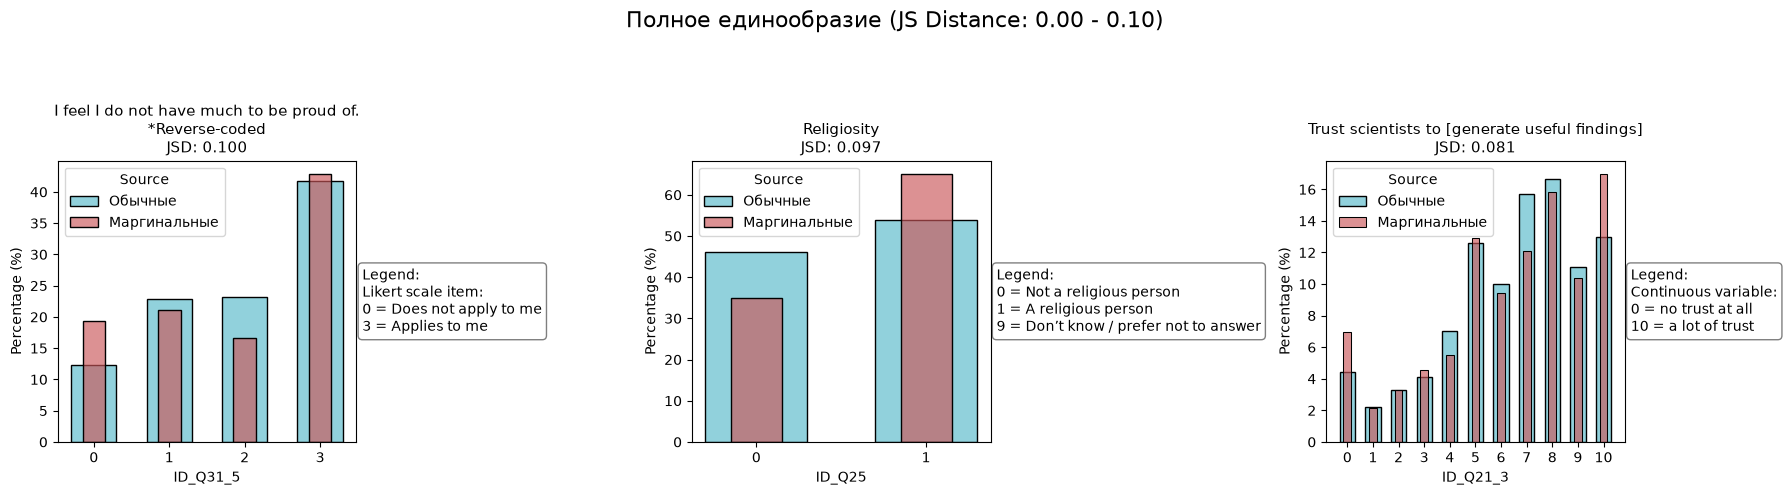

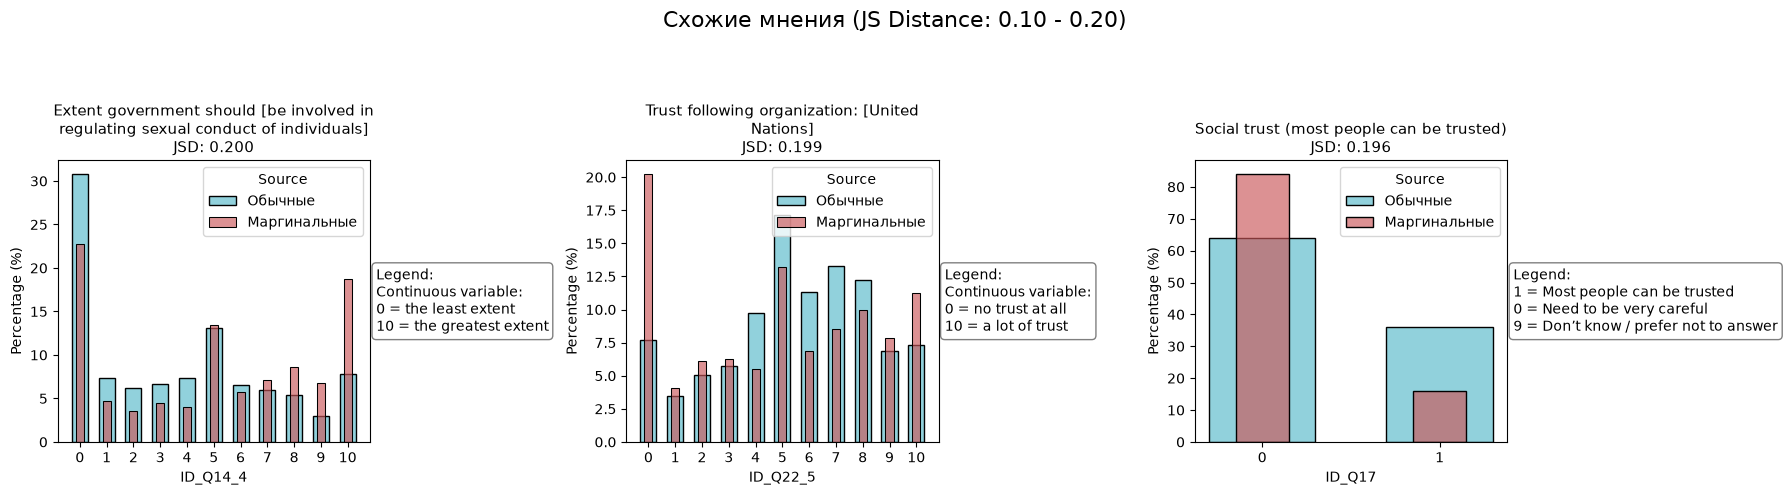

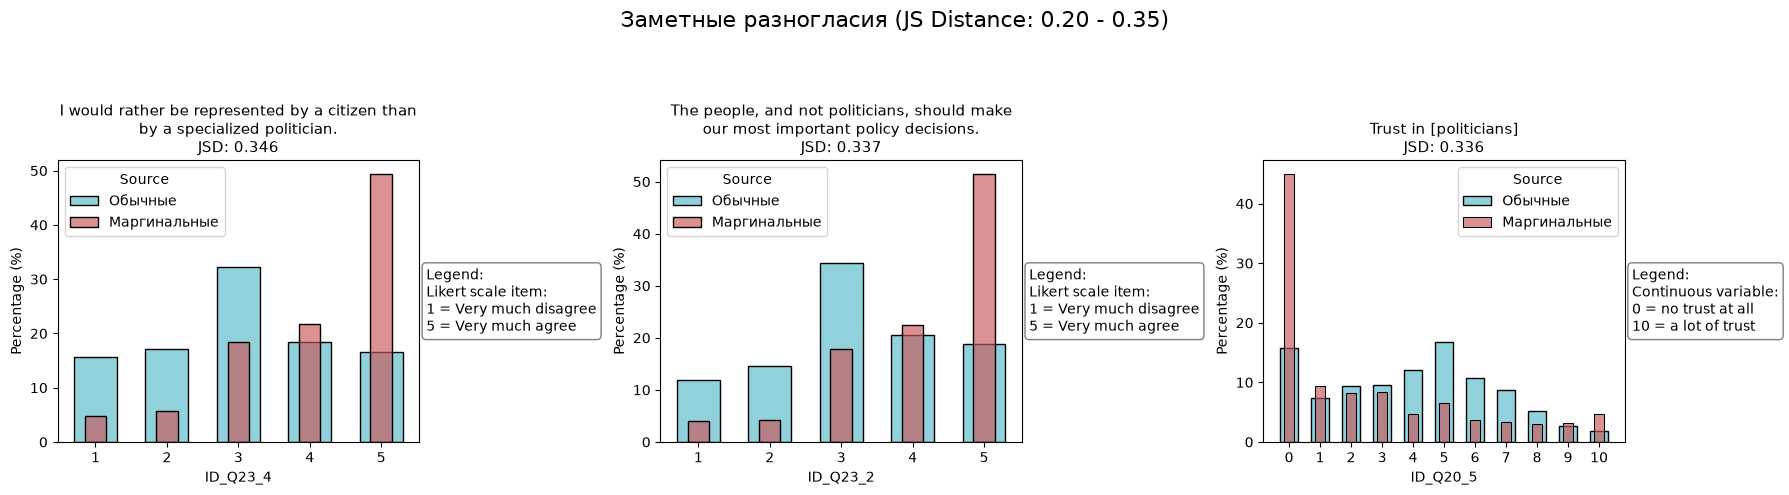

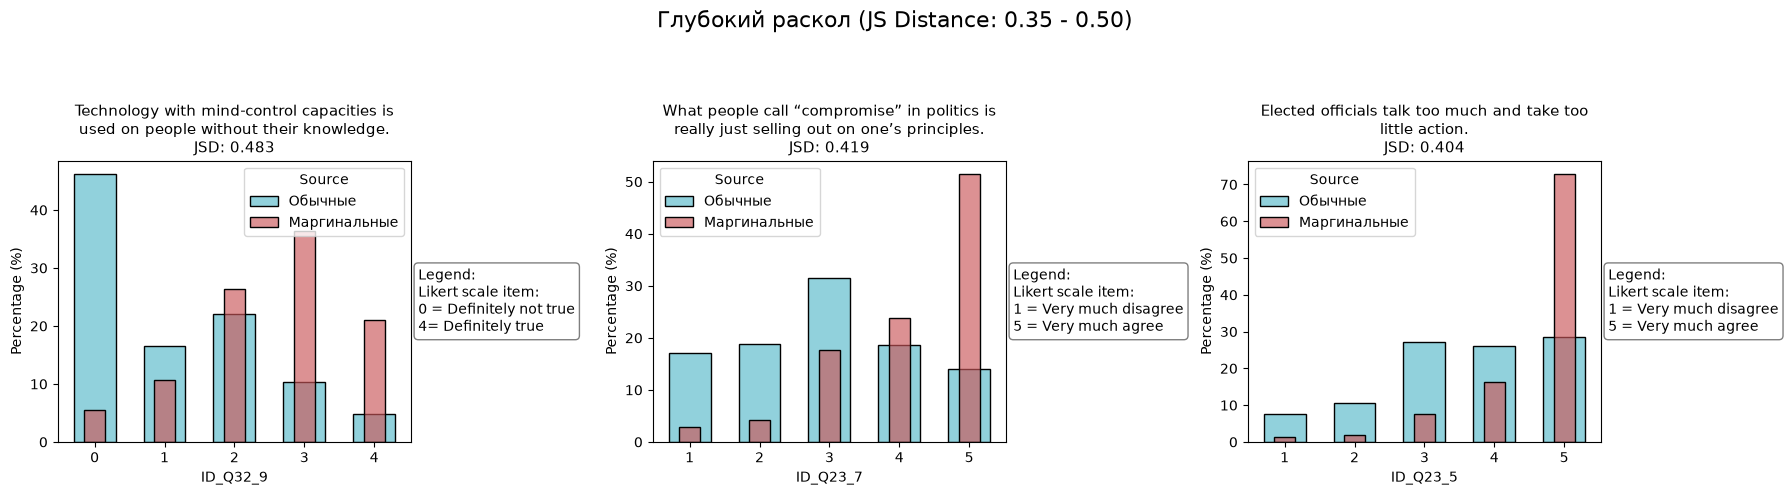

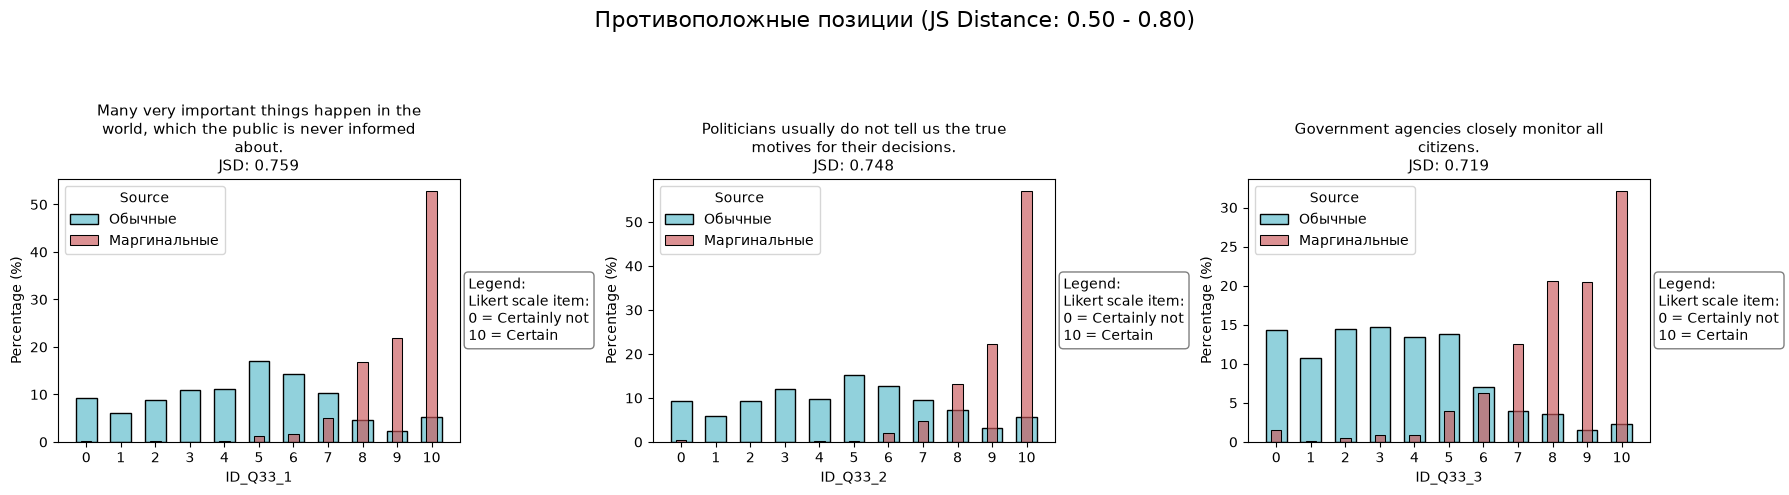

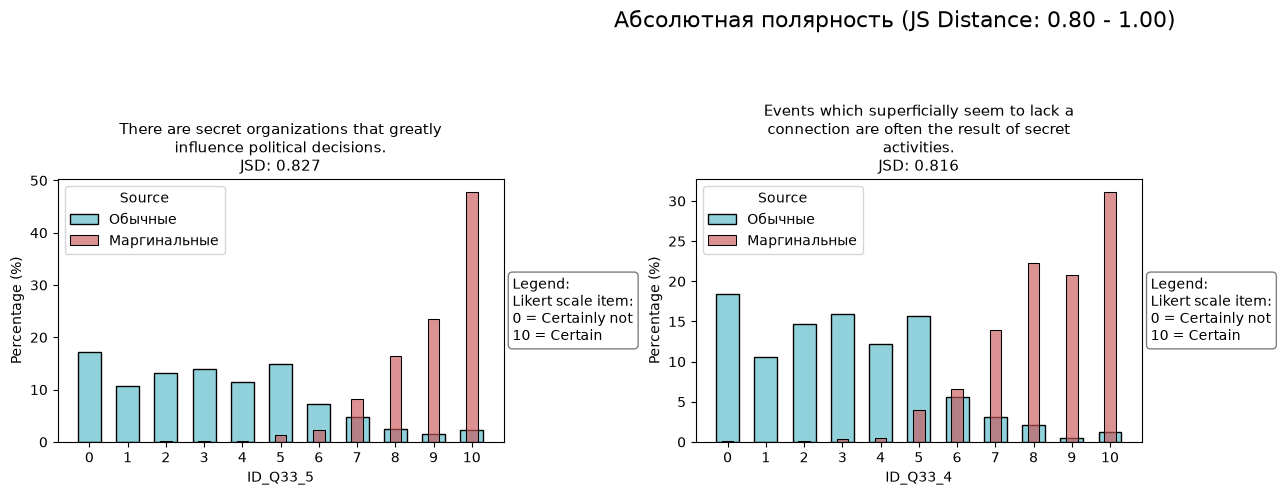


Сравнение «marginal_vs_llama3»: Маргинальные (n=2030) / Llama 3 (n=2030)
Общих вопросов: 128; средняя JS: 0.5603; медиана JS: 0.5884
Нет у второй выборки: 3 вопросов; например ['ID_Q1', 'ID_Q29_1', 'ID_Q29_3']


,js_distance,n_1,n_2
column_name,,,
ID_Q29_2,1.000000,1868,1535
ID_Q35_4,0.859694,1976,2030
ID_Q35_2,0.854917,1986,2030
ID_Q35_3,0.845942,1979,2030
ID_Q35_1,0.833424,1987,2030
...,...,...,...
ID_Q6,0.022602,1980,2030
ID_Q10,0.017235,2014,2030
ID_Q9,0.006324,2028,2030


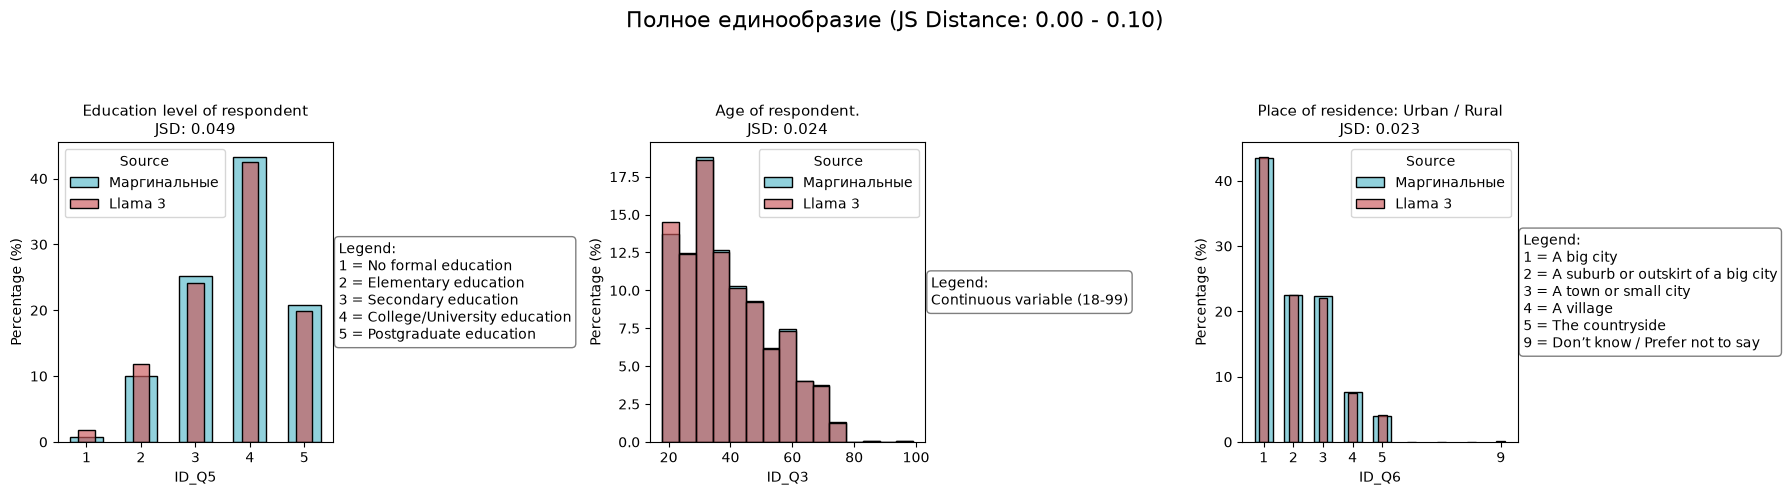

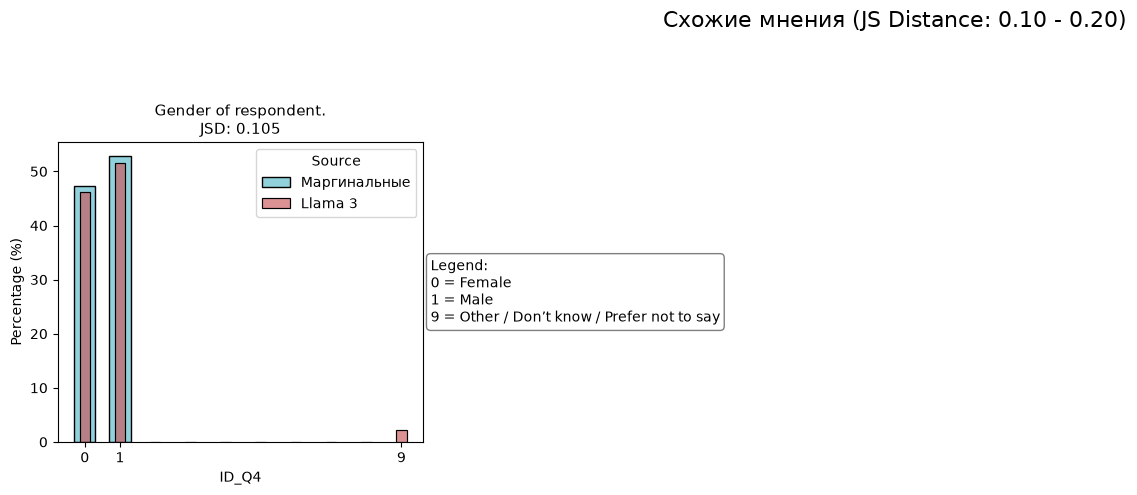

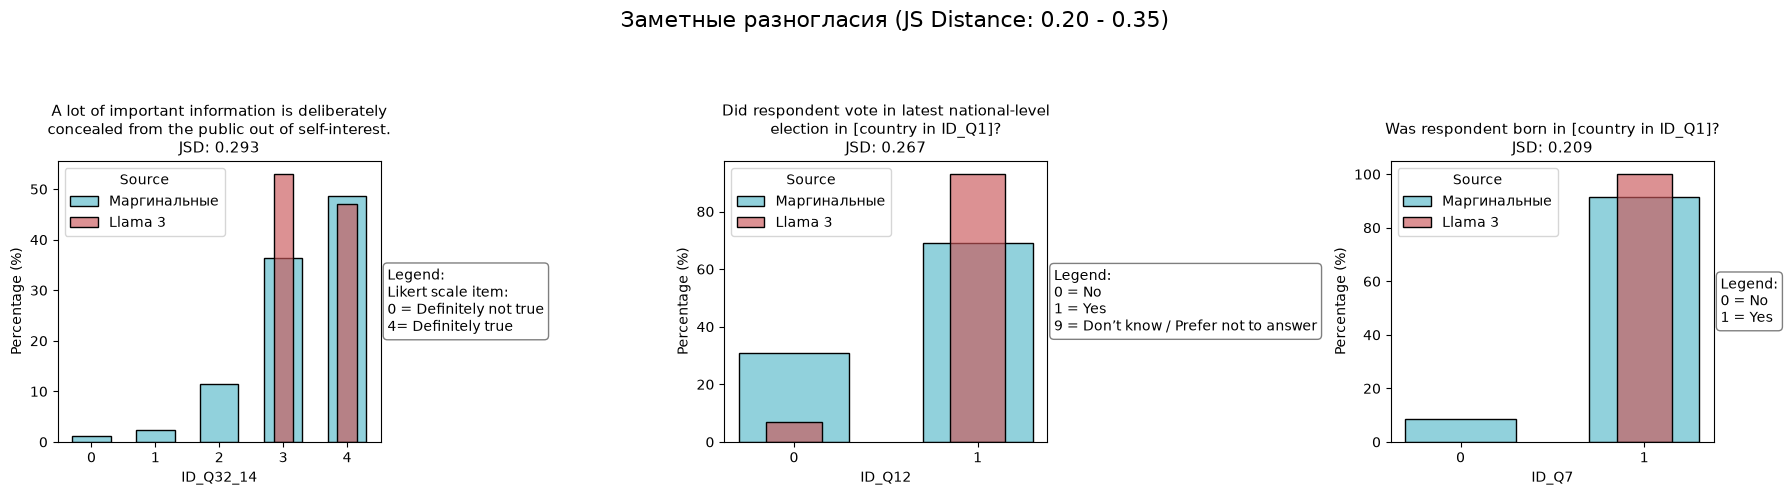

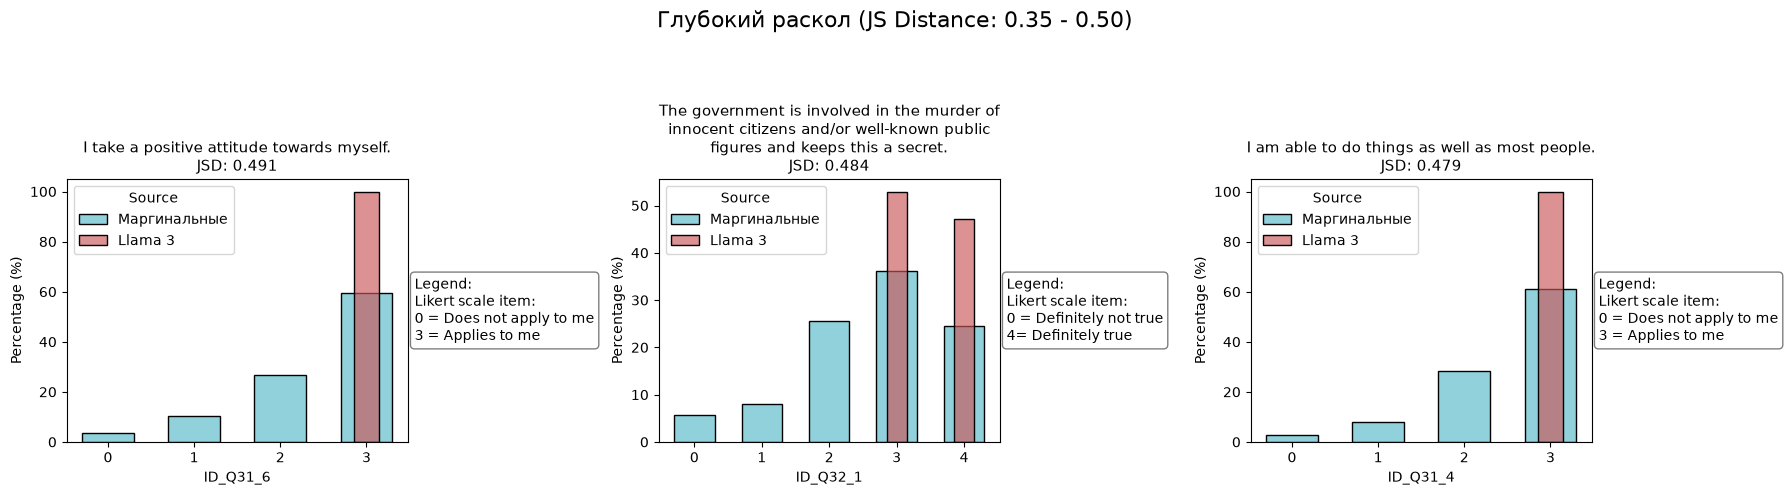

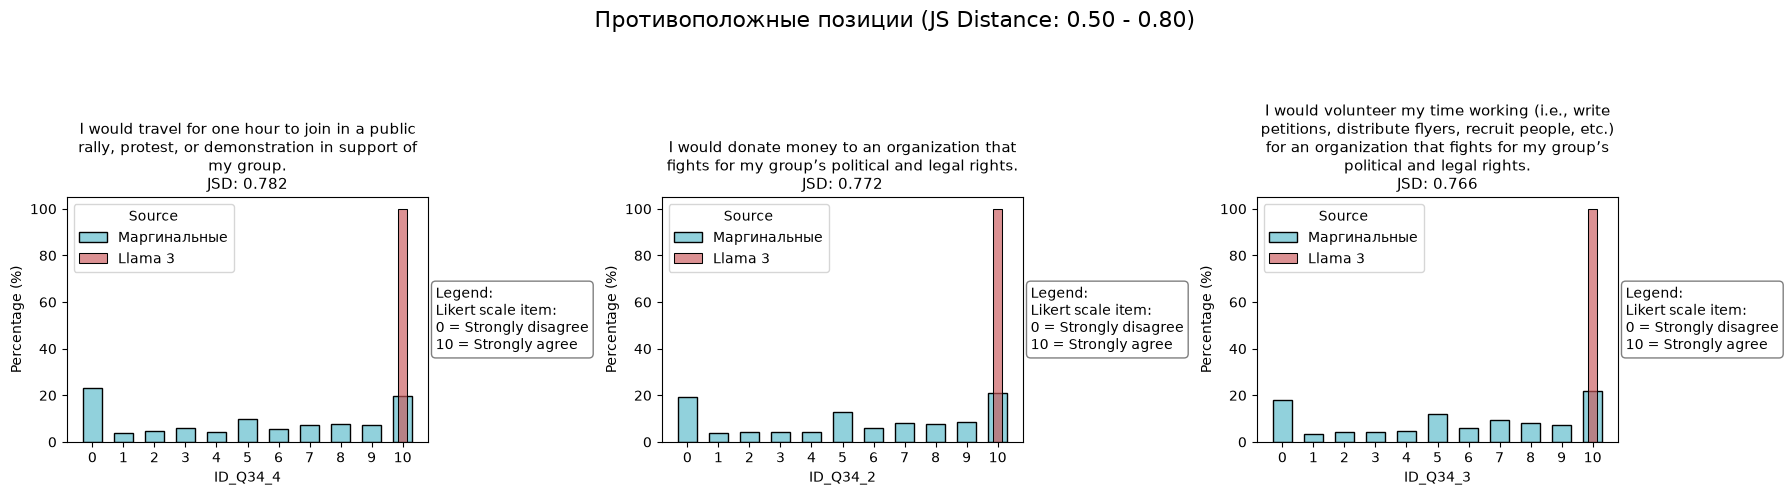

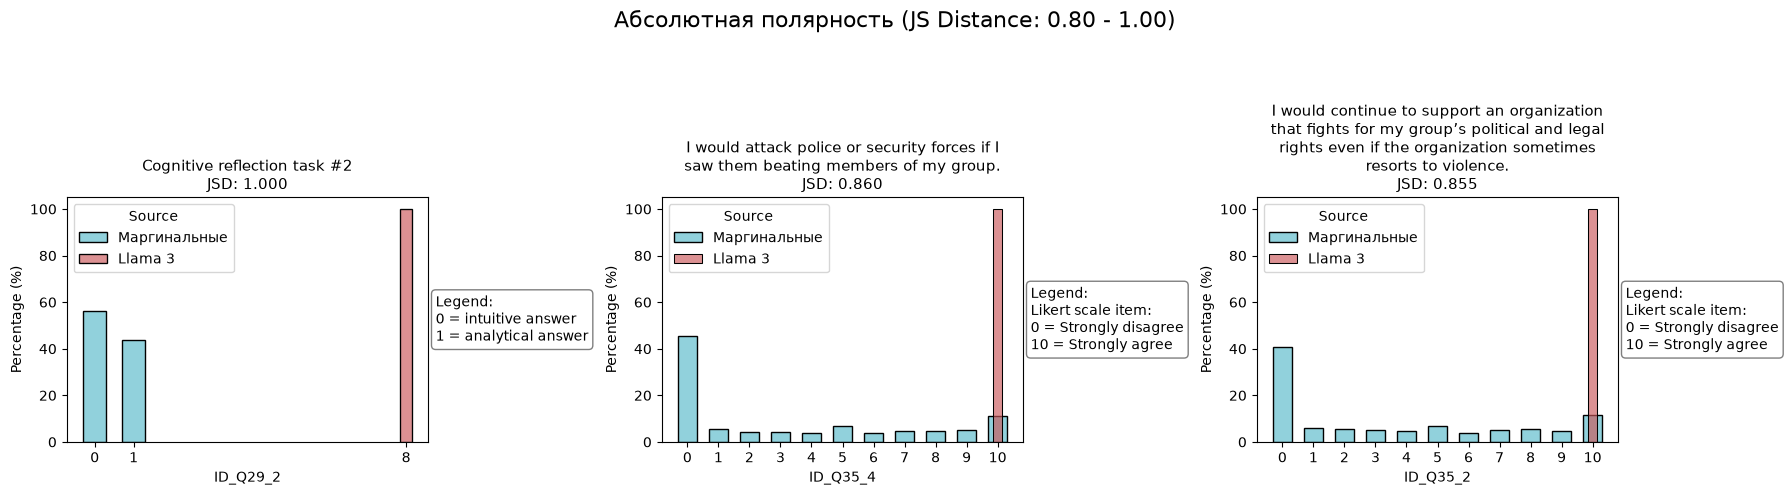

Эталон: реальные маргинальные: 2030 -> 2030; исключено из-за индикаторов: 0
Эталонный StepMix: K=7, BIC=98092.89, средняя max P(class)=0.918


,n_classes,BIC,AIC,iterations,converged
0,1,108559.577,107981.151,2,True
1,2,102556.306,101393.837,37,True
2,3,99903.075,98156.564,98,True
3,4,98950.159,96619.606,600,True
4,5,98499.381,95584.785,230,True
5,6,98163.974,94665.336,215,True
6,7,98092.890,94010.210,342,True
7,8,98224.087,93557.365,433,True


Синтетические маргинальные: 2030 -> 2030; исключено из-за индикаторов: 0
Синтетические: средняя max P(class)=0.755, пропусков из-за новых категорий=0

Доли и определённость классов:


,class_id,expected_n_real,share_real,hard_n_real,mean_max_probability_real,expected_n_synthetic,share_synthetic,hard_n_synthetic,mean_max_probability_synthetic,share_difference,max_probability_difference
0,1,491.205,0.242,505,0.882,578.158,0.285,1075,0.538,0.043,-0.344
1,2,166.120,0.082,166,0.949,0.037,0.000,0,NaN,-0.082,NaN
2,3,485.076,0.239,468,0.919,488.634,0.241,0,NaN,0.002,NaN
3,4,108.903,0.054,109,0.978,0.000,0.000,0,NaN,-0.054,NaN
4,5,208.858,0.103,205,0.938,0.010,0.000,0,NaN,-0.103,NaN
5,6,182.379,0.090,185,0.963,954.957,0.470,955,1.000,0.381,0.037
6,7,387.458,0.191,392,0.903,8.204,0.004,0,NaN,-0.187,NaN



Описание классов:


,class_id,description_real,description_synthetic
0,1,Доля 24.2%. медианный возраст 37 лет; образова...,Доля 28.5%. медианный возраст 33 лет; образова...
1,2,Доля 8.2%. медианный возраст 36 лет; образован...,Доля 0.0%. медианный возраст 41 лет; образован...
2,3,Доля 23.9%. медианный возраст 34 лет; образова...,Доля 24.1%. медианный возраст 33 лет; образова...
3,4,Доля 5.4%. медианный возраст 39 лет; образован...,Доля 0.0%. медианный возраст 33 лет; образован...
4,5,Доля 10.3%. медианный возраст 37 лет; образова...,Доля 0.0%. медианный возраст 33 лет; образован...
5,6,Доля 9.0%. медианный возраст 37 лет; образован...,Доля 47.0%. медианный возраст 40 лет; образова...
6,7,Доля 19.1%. медианный возраст 36 лет; образова...,Доля 0.4%. медианный возраст 33 лет; образован...


... (5 outputs left out)

/tmp/ipykernel_13196/3860268517.py:68: UserWarning: Класс 7: недостаточно респондентов для сопоставления PhiK
  warnings.warn(f'Класс {class_id}: недостаточно респондентов для сопоставления PhiK')


,class_id,n_real_hard,n_synthetic_hard,n_matrix_pairs,mean_abs_phik_difference,n_reference_edges_above_threshold,n_top_reference_edges_tested,n_retained,n_tested,n_stable_reference,n_stable_preserved,edge_retention_rate,stable_edge_retention_rate
0,1,505,1075,136,0.178,36,25,7,25,24,7,0.28,0.292
1,6,185,955,136,0.161,92,25,7,25,25,7,0.28,0.280


Наиболее сильные связи эталона и их воспроизведение:


,class_id,feature_1,feature_2,feature_1_description,feature_2_description,phik_reference,phik_synthetic,abs_difference,bootstrap_fraction_reference,bootstrap_fraction_synthetic,reference_stable,retained_threshold_and_tolerance,both_stable_and_similar
0,1,ID_Q15,ID_Q16,Satisfaction with government over past 12 months.,Satisfaction with democracy,0.733,0.983,0.250,1.0,1.0,True,False,False
1,1,ID_Q15,ID_Q18_1,Satisfaction with government over past 12 months.,Trust in [the government],0.729,0.848,0.119,1.0,1.0,True,True,True
2,1,ID_Q16,ID_Q18_1,Satisfaction with democracy,Trust in [the government],0.675,0.883,0.208,1.0,1.0,True,False,False
3,1,ID_Q32_8,ID_Q32_12,Evidence of alien contact is being concealed f...,Some UFO sightings and rumors are planned or s...,0.633,NaN,NaN,1.0,NaN,True,False,False
4,1,ID_Q32_3,ID_Q32_8,Secret organizations communicate with extrater...,Evidence of alien contact is being concealed f...,0.628,NaN,NaN,1.0,NaN,True,False,False
5,1,ID_Q18_6,ID_Q20_7,Trust in [independent experts],Trust in [scientists],0.626,0.964,0.338,1.0,1.0,True,False,False
6,1,ID_Q3,ID_Q9,Age of respondent.,Employment status,0.576,0.561,0.015,1.0,1.0,True,True,True
7,1,ID_Q32_7,ID_Q32_11,"A small, secret group of people is responsible...",Certain significant events have been the resul...,0.550,NaN,NaN,0.7,NaN,True,False,False
8,1,ID_Q10,ID_Q15,Political ideology,Satisfaction with government over past 12 months.,0.544,0.516,0.028,1.0,1.0,True,True,True
9,1,ID_Q32_4,ID_Q32_5,The spread of certain viruses and/or diseases ...,"Groups of scientists manipulate, fabricate, or...",0.514,NaN,NaN,1.0,NaN,True,False,False


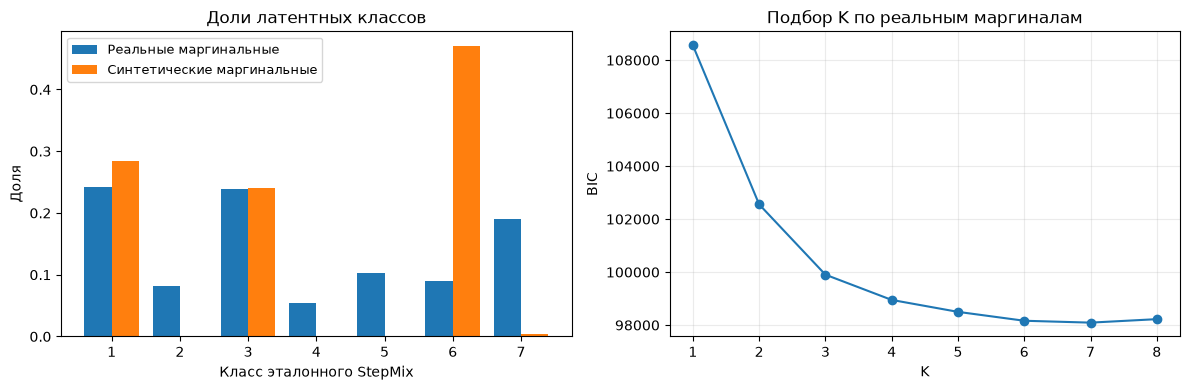

/tmp/ipykernel_13196/485241288.py:70: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout();plt.show()


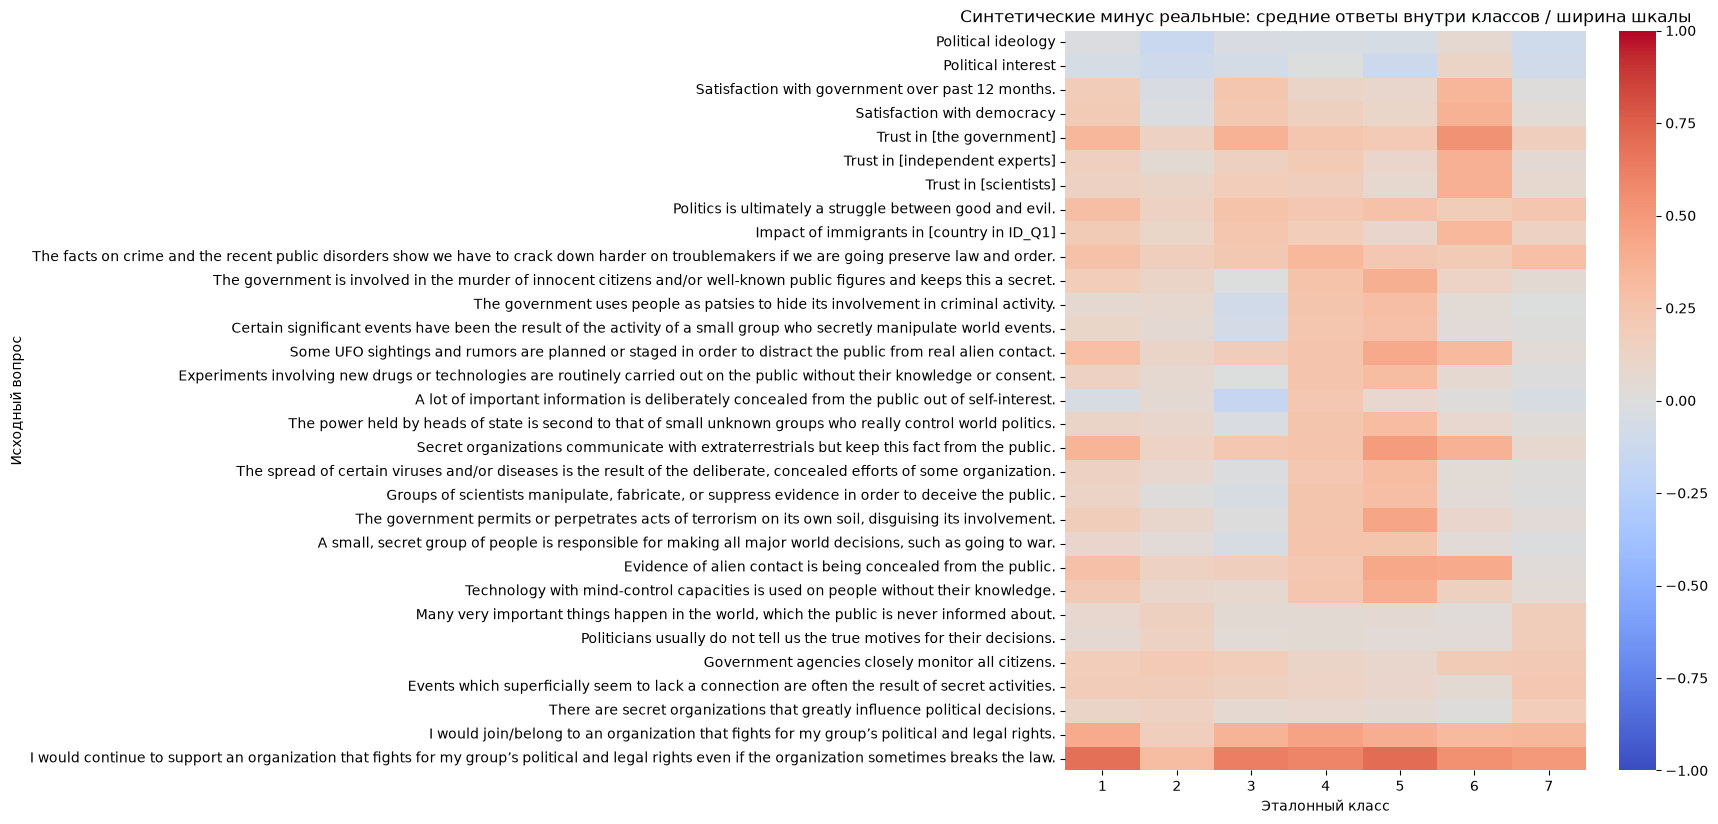

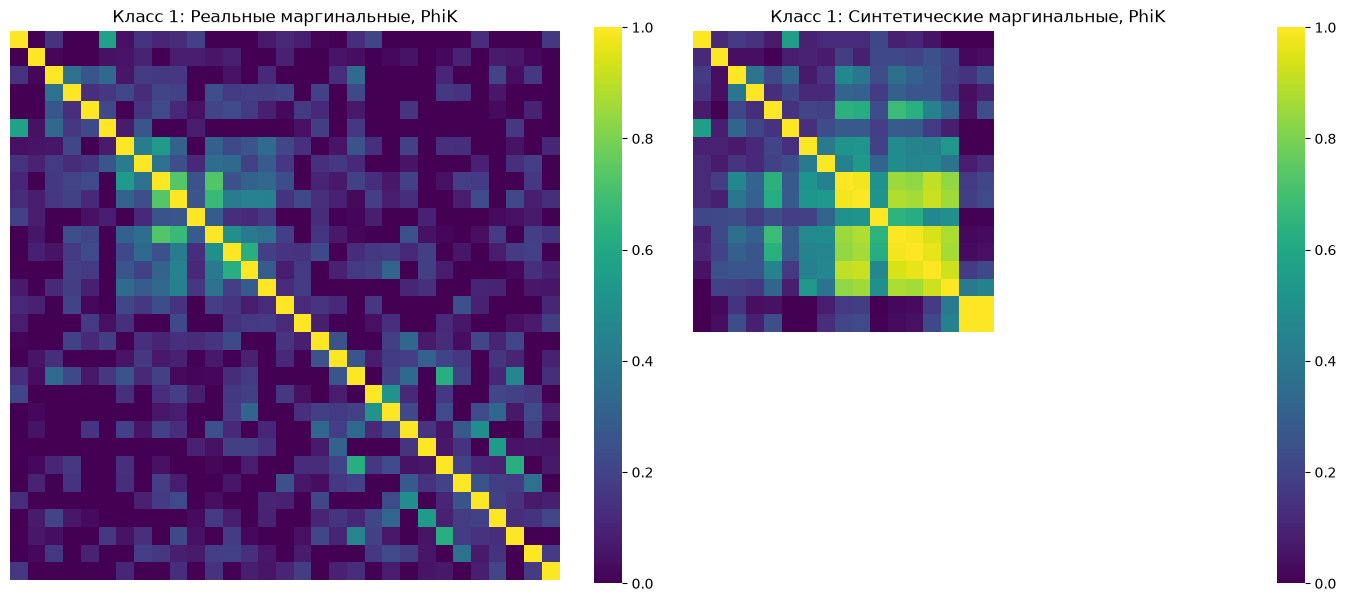

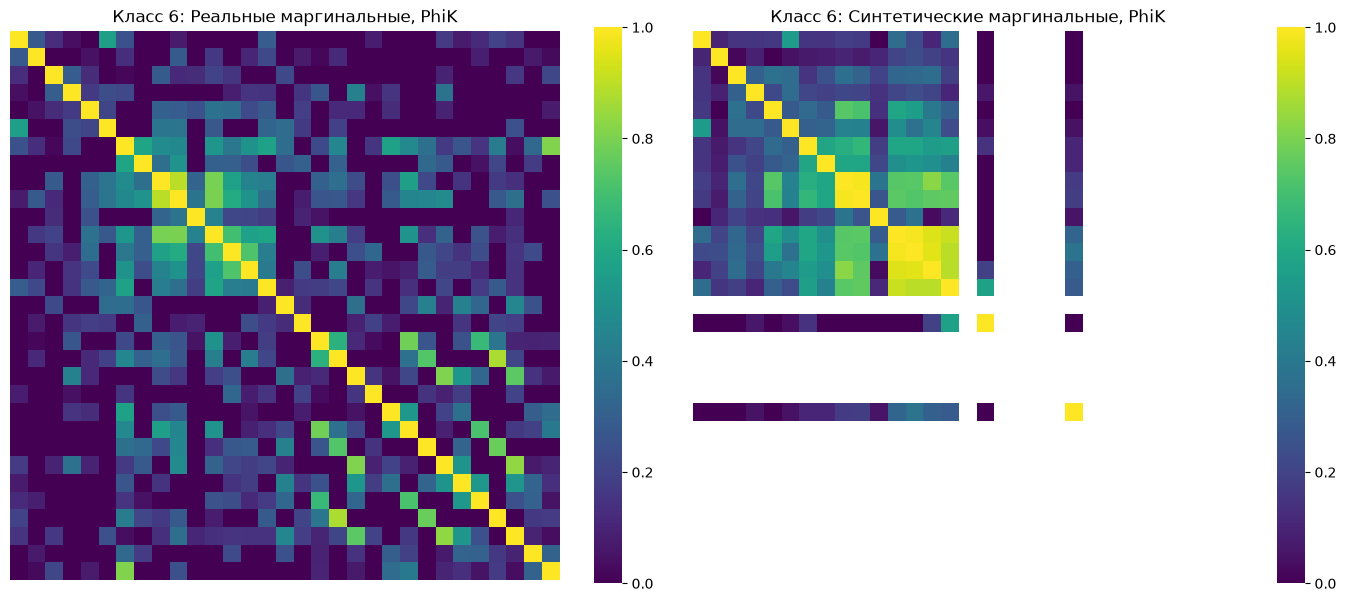

Файлы сохранены: /home/ubuntu/ccrs/ccrs_latent_comparisons/marginal_vs_llama3


In [144]:
# 1. Обычные и маргинальные: ТОЛЬКО JSD и графики
result_normal_marginal = compare_distributions(
    normal, marginal, labels=('Обычные','Маргинальные'),
    comparison_id='normal_vs_marginal'
)

# 2. Синтетические ответы Llama 3 (DataFrame либо CSV)
llama3 = pd.read_csv('synthetic_llama3.csv')
llama3 = llama3.drop(columns=['ID_Q29_1', 'ID_Q29_3'])
result_llama3_js = compare_distributions(
    marginal, llama3, labels=('Маргинальные','Llama 3'), comparison_id='marginal_vs_llama3'
)
result_llama3_latent = compare_latent_structures(
    marginal, llama3, comparison_id='marginal_vs_llama3'
)

# 3. После дообучения: СРАВНИВАЕМ С ТЕМИ ЖЕ ЭТАЛОННЫМИ КЛАССАМИ
# llama3_ft = pd.read_csv('llama3_ft_marginal.csv')
# result_ft_js = compare_distributions(
#     marginal, llama3_ft, labels=('Маргинальные','Llama 3 FT'),
#     comparison_id='marginal_vs_llama3_ft'
# )
# result_ft_latent = compare_latent_structures(
#     marginal, llama3_ft, comparison_id='marginal_vs_llama3_ft',
#     reference=result_llama3_latent['reference']
# )

# Сопоставление средних JSD (по пересечению вопросов):
# compare_history_summary()


In [141]:
for col in ['ID_Q29_1', 'ID_Q29_3']:
    print(col, llama3[col].value_counts(dropna=False))

ID_Q29_1 ID_Q29_1
I am in first place.    1148
I'm in first place.      669
I'm in the lead!         185
I'm in the lead.          21
I'm in first place!        7
Name: count, dtype: int64
ID_Q29_3 ID_Q29_3
Emily.                                         1746
July.                                           147
Mary.                                            74
John.                                            29
I do not know.                                   15
June.                                             8
I think the third daughter's name is Emily.       6
Maria.                                            4
The third daughter's name is Emily.               1
Name: count, dtype: int64
